In [2]:
import numpy as np
import pandas as pd
import matplotlib as plt

### DataReview

In [6]:
battery=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/batteries.csv")
city_daily=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/city_daily_context.csv")
fleet=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/fleet_partners.csv")
riders=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/riders.csv")
station_hourlyStatus=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/station_hourly_status.csv")
station=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/stations.csv")
support_ticket=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/support_tickets.csv")
swap_events=pd.read_csv("/kaggle/input/datasets/sumitrgavali/competition/swap_events.csv")

In [8]:
battery.head()

,battery_id,pack_type,supplier,manufacturing_lot,manufacture_date,commission_date,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,bms_firmware,retired_date,retirement_reason,current_soh_pct
0,BAT-2W-100000,2W_2.1kWh,Cellora,CE-2503,2025-01-30,2025-03-19,2.1,31018,99.9,BMS-4.1,NaN,NaN,79.5
1,BAT-2W-100001,2W_2.1kWh,Cellora,CE-2403,2024-02-27,2024-03-30,2.1,34111,99.2,BMS-4.2,NaN,NaN,79.5
2,BAT-3W-100002,3W_4.8kWh,Cellora,CE-2305,2023-04-15,2023-05-11,4.8,66521,99.5,BMS-4.1,NaN,NaN,87.0
3,BAT-2W-100003,2W_2.1kWh,Kyron,KY-2409,2024-09-28,2024-10-09,2.1,32753,99.5,BMS-4.1,2025-06-15,end_of_life,58.1
4,BAT-2W-100004,2W_2.1kWh,Kyron,KY-2407,2024-11-06,2024-11-21,2.1,31734,99.5,BMS-4.2,2025-06-15,end_of_life,60.6


In [15]:
print("--Battery Columns--")
battery.columns



--Battery Columns--


Index(['battery_id', 'pack_type', 'supplier', 'manufacturing_lot',
       'manufacture_date', 'commission_date', 'rated_capacity_kwh',
       'purchase_cost_inr', 'initial_soh_pct', 'bms_firmware', 'retired_date',
       'retirement_reason', 'current_soh_pct'],
      dtype='object')

In [41]:
battery.info()
battery.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6500 entries, 0 to 6499
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   battery_id          6500 non-null   object 
 1   pack_type           6500 non-null   object 
 2   supplier            6500 non-null   object 
 3   manufacturing_lot   6500 non-null   object 
 4   manufacture_date    6500 non-null   object 
 5   commission_date     6500 non-null   object 
 6   rated_capacity_kwh  6500 non-null   float64
 7   purchase_cost_inr   6500 non-null   int64  
 8   initial_soh_pct     6500 non-null   float64
 9   bms_firmware        6500 non-null   object 
 10  retired_date        1438 non-null   object 
 11  retirement_reason   1438 non-null   object 
 12  current_soh_pct     6500 non-null   float64
dtypes: float64(3), int64(1), object(9)
memory usage: 660.3+ KB


,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,current_soh_pct
count,6500.000000,6500.000000,6500.000000,6500.000000
mean,2.507908,37414.073538,99.191292,76.614585
std,0.967009,12951.496627,0.397470,8.824758
min,2.100000,27473.000000,97.800000,55.400000
25%,2.100000,31339.500000,98.900000,78.400000
50%,2.100000,32250.000000,99.200000,79.800000
75%,2.100000,33397.250000,99.500000,80.800000
max,4.800000,75037.000000,100.000000,88.600000


In [29]:
print("--city_daiy--")
city_daily.columns


--city_daiy--


Index(['city', 'date', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'heat_alert',
       'flood_disruption', 'festival_or_event', 'is_public_holiday',
       'grid_outage_hours', 'competitor_promo_active', 'ecommerce_sale_event'],
      dtype='object')

In [30]:
city_daily.info()
city_daily.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3282 entries, 0 to 3281
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city                     3282 non-null   object 
 1   date                     3282 non-null   object 
 2   max_temp_c               3282 non-null   float64
 3   min_temp_c               3282 non-null   float64
 4   rainfall_mm              3282 non-null   float64
 5   heat_alert               3282 non-null   bool   
 6   flood_disruption         3282 non-null   bool   
 7   festival_or_event        110 non-null    object 
 8   is_public_holiday        3282 non-null   bool   
 9   grid_outage_hours        3282 non-null   float64
 10  competitor_promo_active  3282 non-null   bool   
 11  ecommerce_sale_event     3282 non-null   bool   
dtypes: bool(5), float64(4), object(3)
memory usage: 195.6+ KB


,max_temp_c,min_temp_c,rainfall_mm,grid_outage_hours
count,3282.000000,3282.000000,3282.000000,3282.000000
mean,25.400792,10.706612,5.839275,0.086411
std,9.037847,4.098169,14.637231,0.120668
min,6.700000,1.000000,0.000000,0.000000
25%,19.000000,7.600000,0.000000,0.000000
50%,23.900000,10.100000,0.400000,0.100000
75%,32.200000,13.900000,3.700000,0.100000
max,48.900000,21.200000,235.300000,1.500000


In [18]:
print("--fleet--")
fleet.columns

--fleet--


Index(['partner_id', 'partner_name', 'partner_segment', 'vehicle_class',
       'contract_type', 'contract_start_date', 'discount_pct',
       'amendment_date', 'discount_pct_after_amendment',
       'peak_surcharge_billable', 'payment_terms_days', 'cities_active'],
      dtype='object')

In [32]:
fleet.info()
fleet.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   partner_id                    12 non-null     object 
 1   partner_name                  12 non-null     object 
 2   partner_segment               12 non-null     object 
 3   vehicle_class                 12 non-null     object 
 4   contract_type                 12 non-null     object 
 5   contract_start_date           12 non-null     object 
 6   discount_pct                  12 non-null     float64
 7   amendment_date                1 non-null      object 
 8   discount_pct_after_amendment  1 non-null      float64
 9   peak_surcharge_billable       12 non-null     object 
 10  payment_terms_days            12 non-null     int64  
 11  cities_active                 12 non-null     object 
dtypes: float64(2), int64(1), object(9)
memory usage: 1.3+ KB


,discount_pct,discount_pct_after_amendment,payment_terms_days
count,12.000000,1.0,12.00000
mean,9.416667,28.0,30.00000
std,2.843120,NaN,9.04534
min,5.000000,28.0,15.00000
25%,7.750000,28.0,30.00000
50%,9.500000,28.0,30.00000
75%,11.250000,28.0,30.00000
max,15.000000,28.0,45.00000


In [19]:
print("--riders--")
riders.columns

--riders--


Index(['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone',
       'signup_date', 'signup_channel', 'plan_type', 'declared_shift',
       'age_band', 'kyc_verified', 'home_city'],
      dtype='object')

In [33]:
riders.info()
riders.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   rider_id        20000 non-null  object
 1   partner_id      12372 non-null  object
 2   vehicle_class   20000 non-null  object
 3   vehicle_model   20000 non-null  object
 4   home_zone       20000 non-null  object
 5   signup_date     20000 non-null  object
 6   signup_channel  20000 non-null  object
 7   plan_type       20000 non-null  object
 8   declared_shift  16338 non-null  object
 9   age_band        18453 non-null  object
 10  kyc_verified    20000 non-null  bool  
 11  home_city       20000 non-null  object
dtypes: bool(1), object(11)
memory usage: 1.7+ MB


,rider_id,partner_id,vehicle_class,vehicle_model,home_zone,signup_date,signup_channel,plan_type,declared_shift,age_band,kyc_verified,home_city
count,20000,12372,20000,20000,20000,20000,20000,20000,16338,18453,20000,20000
unique,20000,12,2,8,28,817,4,3,4,4,2,21
top,RD-1019983,FP-01,2W,Zipp E2,JAI-Malviya Nagar,2024-10-22,partner_onboarding,partner_billed,evening,25-34,True,Bengaluru
freq,1,2710,17107,5674,1528,68,9376,12372,5961,6878,19254,4175


In [20]:
print("--station_hourlyStatus--")
station_hourlyStatus.columns

--station_hourlyStatus--


Index(['station_id', 'hour_start', 'charged_2w_avg', 'charged_2w_min',
       'charged_3w_min', 'packs_charging', 'packs_quarantined',
       'chargers_online', 'ambient_temp_c', 'cabinet_temp_c',
       'avg_charge_minutes', 'outage_minutes', 'grid_kwh', 'telemetry_status'],
      dtype='object')

In [35]:
station_hourlyStatus.info()
station_hourlyStatus.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1487712 entries, 0 to 1487711
Data columns (total 14 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   station_id          1487712 non-null  object 
 1   hour_start          1487712 non-null  object 
 2   charged_2w_avg      1478328 non-null  float64
 3   charged_2w_min      1478328 non-null  float64
 4   charged_3w_min      665904 non-null   float64
 5   packs_charging      1478328 non-null  float64
 6   packs_quarantined   1478328 non-null  float64
 7   chargers_online     1487712 non-null  int64  
 8   ambient_temp_c      1478328 non-null  float64
 9   cabinet_temp_c      1478328 non-null  float64
 10  avg_charge_minutes  1478328 non-null  float64
 11  outage_minutes      1487712 non-null  int64  
 12  grid_kwh            1478328 non-null  float64
 13  telemetry_status    1487712 non-null  object 
dtypes: float64(9), int64(2), object(3)
memory usage: 158.9+ MB


,charged_2w_avg,charged_2w_min,charged_3w_min,packs_charging,packs_quarantined,chargers_online,ambient_temp_c,cabinet_temp_c,avg_charge_minutes,outage_minutes,grid_kwh
count,1.478328e+06,1.478328e+06,665904.000000,1.478328e+06,1.478328e+06,1.487712e+06,1.478328e+06,1.478328e+06,1.478328e+06,1.487712e+06,1.478328e+06
mean,8.715770e+00,7.219340e+00,2.541544,4.392111e+00,9.328106e-04,1.475399e+01,1.845586e+01,2.502770e+01,7.479543e+01,1.242176e-02,7.904016e+00
std,3.438186e+00,3.533140e+00,1.052669,2.628867e+00,3.059411e-02,4.164915e+00,8.687845e+00,9.229253e+00,2.014632e+01,8.632217e-01,4.925538e+00
min,8.000000e-02,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,4.100000e+00,3.090000e+01,0.000000e+00,0.000000e+00
25%,6.160000e+00,5.000000e+00,2.000000,2.000000e+00,0.000000e+00,1.200000e+01,1.180000e+01,1.790000e+01,6.270000e+01,0.000000e+00,4.190000e+00
50%,8.340000e+00,7.000000e+00,3.000000,4.000000e+00,0.000000e+00,1.600000e+01,1.720000e+01,2.360000e+01,6.910000e+01,0.000000e+00,7.150000e+00
75%,1.096000e+01,1.000000e+01,3.000000,6.000000e+00,0.000000e+00,1.800000e+01,2.300000e+01,3.020000e+01,8.780000e+01,0.000000e+00,1.071000e+01
max,2.281000e+01,2.200000e+01,5.000000,2.200000e+01,2.000000e+00,2.200000e+01,4.890000e+01,6.050000e+01,3.019000e+02,6.000000e+01,4.644000e+01


In [21]:
print("--station--")
station.columns

--station--


Index(['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type',
       'host_type', 'commissioned_date', 'decommissioned_date',
       'expansion_wave', 'charger_generation', 'slots_2w', 'slots_3w',
       'inventory_target_2w', 'inventory_target_3w', 'monthly_rent_inr',
       'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier',
       'firmware_version', 'firmware_updated_date',
       'competitor_within_1_5km_since'],
      dtype='object')

In [36]:
station.info()
station.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   station_id                     152 non-null    object 
 1   city                           152 non-null    object 
 2   zone                           152 non-null    object 
 3   latitude                       152 non-null    float64
 4   longitude                      152 non-null    float64
 5   location_type                  152 non-null    object 
 6   host_type                      152 non-null    object 
 7   commissioned_date              152 non-null    object 
 8   decommissioned_date            1 non-null      object 
 9   expansion_wave                 152 non-null    object 
 10  charger_generation             152 non-null    object 
 11  slots_2w                       152 non-null    int64  
 12  slots_3w                       152 non-null    int

,latitude,longitude,slots_2w,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh
count,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000
mean,20.130857,76.214074,12.289474,2.223684,22.578947,2.657895,17707.480263,5932.822368,9.301579
std,5.736940,1.994029,3.225789,2.599535,9.701182,3.105443,6354.331398,879.811239,0.772910
min,12.799911,72.886092,8.000000,0.000000,6.000000,0.000000,9054.000000,4503.000000,7.500000
25%,17.234749,73.770932,8.000000,0.000000,15.000000,0.000000,12169.500000,5075.500000,8.785000
50%,18.591899,77.101079,12.000000,0.000000,21.000000,0.000000,16901.500000,5890.000000,9.215000
75%,26.850718,77.605381,16.000000,4.000000,29.000000,5.000000,22012.250000,6687.750000,9.787500
max,28.747185,78.591810,16.000000,6.000000,46.000000,8.000000,35719.000000,7497.000000,11.700000


In [22]:
print("--support_ticket--")
support_ticket.columns

--support_ticket--


Index(['ticket_id', 'rider_id', 'station_id', 'battery_id', 'created_ts',
       'channel', 'category', 'rider_comment', 'priority', 'resolution_status',
       'resolution_hours', 'csat_score'],
      dtype='object')

In [39]:
support_ticket.info()
support_ticket.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44000 entries, 0 to 43999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ticket_id          44000 non-null  object 
 1   rider_id           44000 non-null  object 
 2   station_id         41773 non-null  object 
 3   battery_id         30765 non-null  object 
 4   created_ts         44000 non-null  object 
 5   channel            44000 non-null  object 
 6   category           44000 non-null  object 
 7   rider_comment      44000 non-null  object 
 8   priority           44000 non-null  object 
 9   resolution_status  44000 non-null  object 
 10  resolution_hours   37888 non-null  float64
 11  csat_score         15129 non-null  float64
dtypes: float64(2), object(10)
memory usage: 4.0+ MB


,resolution_hours,csat_score
count,37888.000000,15129.000000
mean,15.951840,3.559720
std,11.004491,1.305327
min,0.900000,1.000000
25%,8.500000,3.000000
50%,13.200000,4.000000
75%,20.200000,5.000000
max,155.800000,5.000000


In [23]:
print("--swap_events--")
swap_events.columns

--swap_events--


Index(['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type',
       'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id',
       'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct',
       'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr',
       'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh',
       'station_firmware', 'sync_mode'],
      dtype='object')

In [40]:
swap_events.info()
swap_events.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3877013 entries, 0 to 3877012
Data columns (total 22 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   event_id                object 
 1   rider_id                object 
 2   station_id              object 
 3   event_ts                object 
 4   event_type              object 
 5   attempt_seq             int64  
 6   queue_wait_sec          int64  
 7   battery_in_id           object 
 8   battery_out_id          object 
 9   soc_in_pct              float64
 10  soh_in_pct              float64
 11  soc_out_pct             float64
 12  soh_out_pct             float64
 13  km_since_last_swap      float64
 14  tariff_code             object 
 15  list_price_inr          float64
 16  discount_inr            float64
 17  amount_charged_inr      float64
 18  payment_mode            object 
 19  energy_to_recharge_kwh  float64
 20  station_firmware        object 
 21  sync_mode               object 

,attempt_seq,queue_wait_sec,soc_in_pct,soh_in_pct,soc_out_pct,soh_out_pct,km_since_last_swap,list_price_inr,discount_inr,amount_charged_inr,energy_to_recharge_kwh
count,3877013.0,3.877013e+06,3.848731e+06,3.848731e+06,3.645809e+06,3.645809e+06,3.848731e+06,3.877013e+06,3.877013e+06,3.877013e+06,3.645809e+06
mean,1.0,2.429536e+02,9.286564e+00,8.816957e+01,9.666453e+01,8.840958e+01,6.203515e+01,6.880879e+01,5.840768e+00,6.013033e+01,2.092923e+00
std,0.0,1.639095e+02,4.445892e+00,7.972944e+00,3.372417e+00,7.451896e+00,2.044107e+01,1.388466e+01,5.636444e+00,2.069786e+01,8.122265e-01
min,1.0,0.000000e+00,1.000000e+00,5.520000e+01,8.000000e+01,5.470000e+01,-2.000000e+01,6.000000e+01,0.000000e+00,0.000000e+00,8.090000e-01
25%,1.0,1.370000e+02,6.000000e+00,8.400000e+01,9.590000e+01,8.430000e+01,5.190000e+01,6.500000e+01,0.000000e+00,5.520000e+01,1.719000e+00
50%,1.0,2.060000e+02,9.300000e+00,8.930000e+01,9.730000e+01,8.920000e+01,6.000000e+01,6.500000e+01,6.500000e+00,5.850000e+01,1.869000e+00
75%,1.0,3.050000e+02,1.250000e+01,9.410000e+01,9.860000e+01,9.390000e+01,6.900000e+01,6.500000e+01,7.800000e+00,6.500000e+01,2.032000e+00
max,1.0,2.400000e+03,2.840000e+01,1.014000e+02,1.030000e+02,1.013000e+02,4.200000e+02,1.100000e+02,3.080000e+01,1.350000e+02,5.519000e+00


In [42]:
import os, re, json, time, warnings, traceback
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10})

C = dict(blue="#1f6feb", red="#d1242f", green="#1a7f37",
         orange="#d98200", purple="#8250df", grey="#6e7781")

# ---------------- CONFIG ----------------
DATA_DIR = os.environ.get("VOLT_DATA_DIR", "/kaggle/input/voltrelay")   # <-- set to your dataset path
OUT_DIR  = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "outputs"
CHART_DIR = os.path.join(OUT_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

DATA_END      = pd.Timestamp("2025-06-30 23:59:59")
FW_BAD        = "v3.2.0"
FW_FROM       = pd.Timestamp("2025-03-10")
FW_TO         = pd.Timestamp("2025-04-15")
FW_SHIFT      = pd.Timedelta(hours=5, minutes=30)
DEDUPE_SEC    = 120
KM_MAX        = 300
RET_LO, RET_HI = 30, 60
LOW_SOH       = 65
LOT_FLAG_PTS  = 8
RECOVERY_RATE = 0.60
TOP_N_FIX     = 15
SERVICE_FAIL  = ["failed_no_charged_battery", "abandoned_queue", "failed_system_error"]

# ---------------- helpers ----------------
RUN_REPORT, M, T = [], {}, {}

def step(name):
    def deco(fn):
        t0 = time.time()
        try:
            fn()
            RUN_REPORT.append((name, "OK", round(time.time() - t0, 1)))
            print(f"✔ {name}  ({time.time() - t0:.1f}s)")
        except Exception as e:
            traceback.print_exc()
            RUN_REPORT.append((name, f"FAILED: {e!r}", round(time.time() - t0, 1)))
            print(f"⚠ {name} FAILED -> {e!r}")
        return fn
    return deco

def save(fig, name):
    fig.savefig(os.path.join(CHART_DIR, name + ".png"), bbox_inches="tight")
    plt.show(); plt.close(fig)

def find_file(base):
    root = base[:-3] if base.endswith(".gz") else base
    for top in [DATA_DIR, "/kaggle/input", "/content", "."]:
        for dp, _, fs in os.walk(top):
            for n in (root, root + ".gz"):
                if n in fs:
                    return os.path.join(dp, n)
    raise FileNotFoundError(base)

def inr(x):
    if pd.isna(x): return "n/a"
    a = abs(x); s = "-" if x < 0 else ""
    return f"{s}₹{a/1e7:.2f} Cr" if a >= 1e7 else \
           f"{s}₹{a/1e5:.2f} L" if a >= 1e5 else f"{s}₹{a:,.0f}"
def pct(x, d=1): return "n/a" if pd.isna(x) else f"{100*x:.{d}f}%"

CITY_RULES = [("bengal|bangal|blr|bnglr", "Bengaluru"),
              ("delhi|ncr|gurug|gurgaon|noida|ghazi|faridab", "Delhi NCR"),
              ("hyd|secunder", "Hyderabad"),
              ("pune|pnq", "Pune"),
              ("mumbai|bombay|navimum|thane|bom", "Mumbai"),
              ("jaipur", "Jaipur")]
ZONE_PREFIX = {"BLR":"Bengaluru","DEL":"Delhi NCR","NCR":"Delhi NCR","HYD":"Hyderabad",
               "PUN":"Pune","PNQ":"Pune","MUM":"Mumbai","BOM":"Mumbai","JAI":"Jaipur"}
def norm_city(s):
    if pd.isna(s): return np.nan
    t = re.sub(r"[^a-z]", "", str(s).lower())
    if t in ("dl","del"): return "Delhi NCR"
    if t in ("mum","mh"): return "Mumbai"
    if t in ("jai","jp"): return "Jaipur"
    for pat, nm in CITY_RULES:
        if re.search(pat, t): return nm
    return str(s).strip().title()

## 2 · Load & clean — every trap handled and logged

| # | Trap | Treatment |
|---|---|---|
| 1 | STN-TST test stations | dropped everywhere |
| 2 | Firmware v3.2.0 timestamp bug (10 Mar–14 Apr 2025) | +5h30m restored |
| 3 | Near-duplicates (offline_batch ≤120 s) | dropped |
| 4 | home_city spellings | zone-prefix → keyword standardisation |
| 5 | SoC/SoH > 100 | capped at 100 |
| 6 | km_since_last_swap outliers | NaN |
| 7 | Blank telemetry | kept as NaN, never 0 |
| 8 | Non-completed attempts | counted in fail_rate, not revenue |
| 9 | Ticket category unreliable | re-classified from comments |

In [43]:
CLEAN_LOG = []
def log(step_, n, note):
    CLEAN_LOG.append(dict(step=step_, rows_affected=int(n), note=note))
    print(f"  [{step_}] {int(n):,} — {note}")

@step("Load + Clean")
def _():
    global ev, st, hr, tk, rd, cdc, bt, fp, RAW_ROWS

    # ---------- load ----------
    st  = pd.read_csv(find_file("stations.csv"))
    rd  = pd.read_csv(find_file("riders.csv"))
    bt  = pd.read_csv(find_file("batteries.csv"))
    fp  = pd.read_csv(find_file("fleet_partners.csv"))
    cdc = pd.read_csv(find_file("city_daily_context.csv"))
    tk  = pd.read_csv(find_file("support_tickets.csv"))
    hr  = pd.read_csv(find_file("station_hourly_status.csv.gz"))
    EV_CAT = ["rider_id","station_id","event_type","battery_in_id","battery_out_id",
              "tariff_code","payment_mode","station_firmware","sync_mode"]
    ev = pd.read_csv(find_file("swap_events.csv.gz"),
                     usecols=lambda c: c not in ("event_id","attempt_seq"),
                     dtype={c: "category" for c in EV_CAT})
    RAW_ROWS = {"swap_events": len(ev), "station_hourly": len(hr), "riders": len(rd),
                "batteries": len(bt), "tickets": len(tk), "stations": len(st),
                "city_daily": len(cdc), "fleet": len(fp)}
    print("loaded:", RAW_ROWS)

    # ---------- 1) test stations ----------
    tst = [s for s in st.station_id.astype(str) if s.startswith("STN-TST")]
    n0 = int(ev.station_id.isin(tst).sum())
    ev = ev[~ev.station_id.isin(tst)].copy()
    ev["station_id"] = ev.station_id.cat.remove_unused_categories()
    st = st[~st.station_id.isin(tst)].reset_index(drop=True)
    hr = hr[~hr.station_id.isin(tst)].reset_index(drop=True)
    tk = tk[~tk.station_id.isin(tst)].reset_index(drop=True)
    log("1 test stations", n0, f"events at {len(tst)} test stations dropped")

    # ---------- dates ----------
    ev["event_ts"]   = pd.to_datetime(ev["event_ts"])
    hr["hour_start"] = pd.to_datetime(hr["hour_start"])
    tk["created_ts"] = pd.to_datetime(tk["created_ts"])
    for c in ["commissioned_date","decommissioned_date","firmware_updated_date","competitor_within_1_5km_since"]:
        st[c] = pd.to_datetime(st[c], errors="coerce")
    for c in ["manufacture_date","commission_date","retired_date"]:
        bt[c] = pd.to_datetime(bt[c], errors="coerce")
    for c in ["contract_start_date","amendment_date"]:
        fp[c] = pd.to_datetime(fp[c], errors="coerce")
    rd["signup_date"] = pd.to_datetime(rd["signup_date"], errors="coerce")
    cdc["date"] = pd.to_datetime(cdc["date"])

    # ---------- 2) firmware timestamp bug ----------
    m = ev.station_firmware.eq(FW_BAD).to_numpy() & \
        (ev.event_ts >= FW_FROM).to_numpy() & (ev.event_ts < FW_TO).to_numpy()
    ev["ts_fixed"] = m
    ev.loc[m, "event_ts"] = ev.loc[m, "event_ts"] + FW_SHIFT
    log("2 firmware timestamp bug", m.sum(), f"{FW_BAD} events +5h30m")

    # ---------- 3) near-duplicates ----------
    rdr = ev.rider_id.cat.codes.to_numpy(); stn = ev.station_id.cat.codes.to_numpy()
    bi  = ev.battery_in_id.cat.codes.to_numpy(); bo = ev.battery_out_id.cat.codes.to_numpy()
    ts_i = ev.event_ts.to_numpy("datetime64[ns]").astype("int64")
    order = np.lexsort((ts_i, bo, bi, stn, rdr))
    r_, s_, bi_, bo_, t_ = rdr[order], stn[order], bi[order], bo[order], ts_i[order]
    same = (r_[1:]==r_[:-1]) & (s_[1:]==s_[:-1]) & (bi_[1:]==bi_[:-1]) & (bo_[1:]==bo_[:-1]) & ((bi_[1:]>=0)|(bo_[1:]>=0))
    close = same & ((t_[1:]-t_[:-1])/1e9 <= DEDUPE_SEC)
    offline = ev.sync_mode.eq("offline_batch").to_numpy()[order][1:]
    drop_sorted = np.zeros(len(ev), bool); drop_sorted[1:] = close & offline
    drop = np.zeros(len(ev), bool); drop[order] = drop_sorted
    ev = ev[~drop].reset_index(drop=True)
    for c in ["rider_id","station_id","battery_in_id","battery_out_id"]:
        ev[c] = ev[c].cat.remove_unused_categories()
    log("3 near-duplicates", drop.sum(), f"offline_batch ≤{DEDUPE_SEC}s retries removed")
    M["duplicates_removed"] = int(drop.sum())

    # ---------- 5) SoC/SoH caps ----------
    over = 0
    for c in ["soc_in_pct","soc_out_pct","soh_in_pct","soh_out_pct"]:
        over += int((ev[c] > 100).sum()); ev[c] = ev[c].clip(upper=100)
    log("5 SoC/SoH >100", over, "capped at 100 (calibration drift)")

    # ---------- 6) km outliers ----------
    bad_km = ev.km_since_last_swap.notna() & ~ev.km_since_last_swap.between(0, KM_MAX)
    log("6 km outliers", bad_km.sum(), f"km outside [0,{KM_MAX}] → NaN")
    ev.loc[bad_km, "km_since_last_swap"] = np.nan

    # ---------- 4) city standardisation ----------
    rd["city_raw"] = rd["home_city"]
    zp = rd["home_zone"].astype(str).str.split("-").str[0].str.upper().map(ZONE_PREFIX)
    kw = rd["home_city"].map(norm_city)
    rd["home_city"] = zp.fillna(kw)
    log("4 home_city", int((rd.city_raw != rd.home_city).sum()),
        f"{rd.city_raw.nunique()} → {rd.home_city.nunique()} cities")
    st["city"]  = st.city.map(norm_city)
    cdc["city"] = cdc.city.map(norm_city)
    rd["partner_id"] = rd.partner_id.replace("", np.nan)
    rd["age_band"] = rd.age_band.fillna("unknown")
    rd["declared_shift"] = rd.declared_shift.fillna("unknown")

    # ---------- 7) telemetry flags ----------
    tel_ok = hr.telemetry_status.eq("ok")
    log("7 hourly telemetry", int((~tel_ok).sum()), "partial/missing kept as NaN")
    hr["stockout_2w"] = np.where(hr.charged_2w_min.notna(), (hr.charged_2w_min == 0).astype(float), np.nan)
    hr["stockout_3w"] = np.where(hr.charged_3w_min.notna(), (hr.charged_3w_min == 0).astype(float), np.nan)
    hr["charger_util"] = np.where(hr.chargers_online > 0, hr.packs_charging / hr.chargers_online, np.nan)

    # ---------- 9) ticket re-classification ----------
    KW = [("stockout",      r"no battery|not available|unavailable|stock|khali|empty|nahi mil|available nahi|koi battery nahi"),
          ("battery_range", r"range|backup|\bkm\b|jaldi|khatam|drain|dead|low charge|charge nahi|kam chal|health|weak|battery|vehicle|scooter|bike|gaadi"),
          ("queue_wait",    r"queue|wait|line|intezaar|lamba|der "),
          ("payment",       r"payment|deduct|refund|paisa|paise|double|upi|wallet|charged|amount"),
          ("app",           r"\bapp\b|login|otp|crash|hang|update"),
          ("machine",       r"error|cabinet|door|machine|stuck|nahi khul|not open|system|slot")]
    def reclass(txt):
        t = str(txt).lower()
        for lab, pat in KW:
            if re.search(pat, t): return lab
        return None
    tk["category_clean"] = tk.apply(lambda r: reclass(r.rider_comment) or r.category, axis=1).fillna("other")
    log("9 ticket reclass", int((tk.category_clean != tk.category).sum()),
        "comments override agent label where text is clear")

    # ---------- event flags ----------
    ev["month"]          = ev.event_ts.dt.to_period("M").dt.to_timestamp()
    ev["hour"]           = ev.event_ts.dt.hour
    ev["dow"]            = ev.event_ts.dt.dayofweek
    ev["date"]           = ev.event_ts.dt.normalize()
    ev["is_completed"]   = ev.event_type.eq("swap_completed")
    ev["is_service_fail"]= ev.event_type.isin(SERVICE_FAIL)
    ev["is_stockout"]    = ev.event_type.eq("failed_no_charged_battery")
    ev["is_abandon"]     = ev.event_type.eq("abandoned_queue")
    ev["is_sys_err"]     = ev.event_type.eq("failed_system_error")
    ev["is_cancel"]      = ev.event_type.eq("cancelled_by_rider")
    ev["wait_min"]       = ev.queue_wait_sec / 60.0
    ev["discount_ratio"] = np.where(ev.list_price_inr > 0, ev.discount_inr / ev.list_price_inr, 0)

    # ---------- master merges ----------
    ev["station_id_str"] = ev.station_id.astype(str)
    ev["rider_id_str"]   = ev.rider_id.astype(str)
    ev = ev.merge(st[["station_id","city","zone","location_type","host_type","charger_generation",
                      "connectivity_tier","expansion_wave","commissioned_date","slots_2w","slots_3w",
                      "grid_tariff_inr_kwh","monthly_rent_inr","monthly_maintenance_inr",
                      "latitude","longitude"]],
                  left_on="station_id_str", right_on="station_id", how="left", suffixes=("","_st"))
    ev = ev.merge(rd[["rider_id","vehicle_class","vehicle_model","home_city","home_zone",
                      "signup_date","signup_channel","plan_type","age_band","kyc_verified","partner_id"]],
                  left_on="rider_id_str", right_on="rider_id", how="left", suffixes=("","_rd"))
    ev = ev.merge(fp[["partner_id","partner_name","partner_segment","contract_type",
                      "discount_pct","amendment_date","discount_pct_after_amendment",
                      "peak_surcharge_billable","payment_terms_days"]],
                  on="partner_id", how="left")
    ev["city_event"] = ev.city
    ev["age_days_station"] = (ev.event_ts - ev.commissioned_date).dt.days

    # ---------- unit economics ----------
    ev["energy_cost"] = np.where(ev.is_completed, ev.energy_to_recharge_kwh * ev.grid_tariff_inr_kwh, 0.0)
    avg_pack_cost = bt.groupby("pack_type").purchase_cost_inr.median()
    avg_cycles    = 1200.0
    m2 = ev.is_completed
    ev.loc[m2, "wear_cost"] = ev.loc[m2].apply(
        lambda r: avg_pack_cost.get("3W_4.8kWh" if r.vehicle_class == "3W" else "2W_2.1kWh", 40000) / avg_cycles, axis=1)
    st["monthly_opex"] = st.monthly_rent_inr.fillna(0) + st.monthly_maintenance_inr.fillna(0)
    ma = ev.groupby(["station_id_str","month"]).size().rename("att").reset_index()
    ma = ma.merge(st[["station_id","monthly_opex"]], left_on="station_id_str",
                  right_on="station_id", how="left")
    ma["stn_cost_per_attempt"] = ma.monthly_opex / ma.att.clip(lower=1)
    ev = ev.merge(ma[["station_id_str","month","stn_cost_per_attempt"]],
                  on=["station_id_str","month"], how="left")
    ev["station_cost"] = np.where(ev.is_completed, ev.stn_cost_per_attempt.fillna(0), 0.0)
    ev["contribution"] = np.where(ev.is_completed,
                                   ev.amount_charged_inr - ev.energy_cost - ev.wear_cost - ev.station_cost, 0.0)
    ev["rev"] = np.where(ev.is_completed, ev.amount_charged_inr, 0.0)
    ev["is_partner"] = ev.partner_id.notna()
    print(f"master events: {len(ev):,}")

loaded: {'swap_events': 3877013, 'station_hourly': 1487712, 'riders': 20000, 'batteries': 6500, 'tickets': 44000, 'stations': 152, 'city_daily': 3282, 'fleet': 12}
  [1 test stations] 62,031 — events at 2 test stations dropped
  [2 firmware timestamp bug] 139,490 — v3.2.0 events +5h30m
  [3 near-duplicates] 0 — offline_batch ≤120s retries removed
  [5 SoC/SoH >100] 9,684 — capped at 100 (calibration drift)
  [6 km outliers] 15,287 — km outside [0,300] → NaN
  [4 home_city] 585 — 21 → 6 cities
  [7 hourly telemetry] 46,131 — partial/missing kept as NaN
  [9 ticket reclass] 36,588 — comments override agent label where text is clear
master events: 3,814,982
✔ Load + Clean  (120.5s)


## 3 · KPI helper + station scorecard
The reusable `kpi_table(df, dim)` powers every per-dimension analysis downstream.

In [60]:
def kpi_table(df, dim):
    g = df.groupby(dim, observed=True)
    t = g.agg(attempts=("is_completed","size"),
              completed=("is_completed","sum"),
              cancels=("is_cancel","sum"),
              service_fails=("is_service_fail","sum"),
              stockouts=("is_stockout","sum"),
              abandons=("is_abandon","sum"),
              sys_errs=("is_sys_err","sum"),
              revenue=("rev","sum"),
              contribution=("contribution","sum"),
              energy=("energy_cost","sum"),
              wear=("wear_cost","sum"),
              station_cost=("station_cost","sum")).reset_index()
    t["fail_rate"]       = t.service_fails / t.attempts
    t["stockout_rate"]   = t.stockouts / t.attempts
    t["abandon_rate"]    = t.abandons / t.attempts
    t["sys_err_rate"]    = t.sys_errs / t.attempts
    t["cancel_rate"]     = t.cancels / t.attempts
    t["rev_per_swap"]    = t.revenue / t.completed.clip(lower=1)
    t["margin_per_swap"] = t.contribution / t.completed.clip(lower=1)
    return t

@step("Station scorecard")
def _():
    sp = kpi_table(ev, "station_id_str")
    sp = sp.merge(st[["station_id","city","zone","location_type","host_type","charger_generation",
                      "connectivity_tier","expansion_wave","commissioned_date","slots_2w","slots_3w",
                      "monthly_opex","grid_tariff_inr_kwh","latitude","longitude"]],
                  left_on="station_id_str", right_on="station_id", how="left")
    # monthly telemetry → station level
    hh = hr.copy(); hh["station_id_str"] = hh.station_id.astype(str)
    hh["month"] = hh.hour_start.dt.to_period("M").dt.to_timestamp()
    tel = hh.groupby(["station_id_str","month"], observed=True).agg(
        stockout_hours_2w=("stockout_2w","mean"),
        avg_charge_min=("avg_charge_minutes","mean"),
        charger_util_mean=("charger_util","mean"),
        cabinet_temp_mean=("cabinet_temp_c","mean"),
        outage_minutes=("outage_minutes","sum"),
        telemetry_ok_share=("telemetry_status", lambda s: (s=="ok").mean())).reset_index()
    tel_agg = tel.groupby("station_id_str").agg(
        stockout_hours_2w=("stockout_hours_2w","mean"),
        avg_charge_min=("avg_charge_min","mean"),
        charger_util_mean=("charger_util_mean","mean"),
        cabinet_temp_mean=("cabinet_temp_mean","mean"),
        outage_minutes=("outage_minutes","sum"),
        telemetry_ok_share=("telemetry_ok_share","mean"))
    sp = sp.merge(tel_agg, left_on="station_id_str", right_index=True, how="left")
    # tickets
    tk_st = tk.groupby(tk.station_id.astype(str)).size().rename("tickets")
    sp = sp.merge(tk_st, left_on="station_id_str", right_index=True, how="left")
    sp["tickets"] = sp.tickets.fillna(0)
    sp["tickets_per_1k"] = sp.tickets / sp.attempts * 1000
    # wait p90 + excess failures
    wait_p90 = ev.groupby("station_id_str", observed=True).wait_min.quantile(0.9).rename("p90_wait_min")
    sp = sp.merge(wait_p90, left_on="station_id_str", right_index=True, how="left")
    net_p = sp.service_fails.sum() / sp.attempts.sum()
    sp["excess_fails"]      = (sp.fail_rate - net_p) * sp.attempts
    sp["network_fail_rate"] = net_p
    T["station_perf"]           = sp.set_index("station_id_str")
    M["network_fail_rate"]      = float(net_p)
    M["network_rev_per_swap"]   = float(sp.revenue.sum() / sp.completed.sum())
    M["network_margin_per_swap"]= float(sp.contribution.sum() / sp.completed.sum())
    M["revenue"]                = float(ev.rev.sum())
    M["completed"]              = int(ev.is_completed.sum())
    print(f"stations: {len(sp)}, network fail {net_p:.2%}, "
          f"rev/swap {inr(M['network_rev_per_swap'])}, margin/swap {inr(M['network_margin_per_swap'])}")

stations: 150, network fail 5.55%, rev/swap ₹64, margin/swap ₹2
✔ Station scorecard  (2.4s)


## 4 · Exploratory data analysis
Shape of the cleaned network before the business questions.

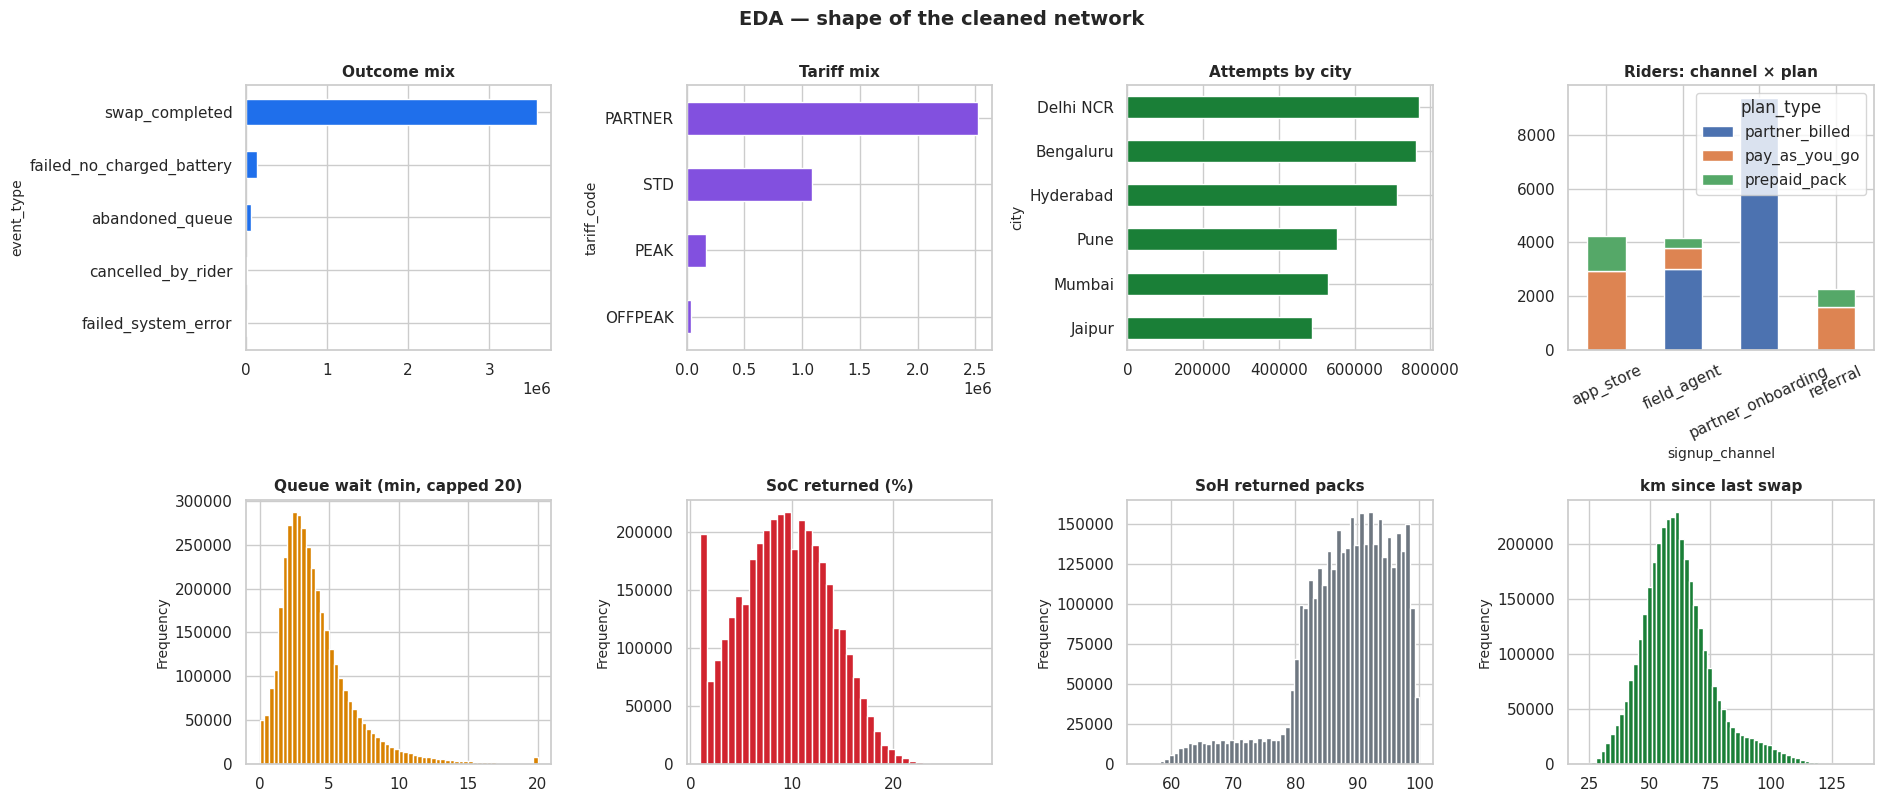

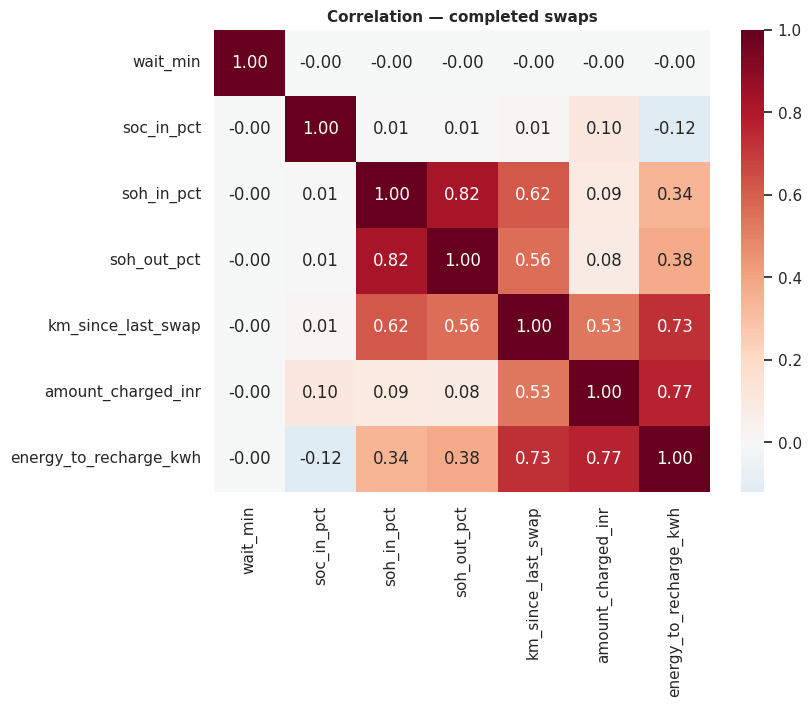

✔ EDA overview  (7.0s)


In [45]:
@step("EDA overview")
def _():
    fig, ax = plt.subplots(2, 4, figsize=(19, 8))
    ev.event_type.value_counts().plot.barh(ax=ax[0,0], color=C["blue"]); ax[0,0].set_title("Outcome mix"); ax[0,0].invert_yaxis()
    ev.tariff_code.value_counts().plot.barh(ax=ax[0,1], color=C["purple"]); ax[0,1].set_title("Tariff mix"); ax[0,1].invert_yaxis()
    ev.groupby("city", observed=True).size().sort_values().plot.barh(ax=ax[0,2], color=C["green"]); ax[0,2].set_title("Attempts by city")
    rd.groupby(["signup_channel","plan_type"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=ax[0,3])
    ax[0,3].set_title("Riders: channel × plan"); ax[0,3].tick_params(axis="x", rotation=25)
    ev.wait_min.clip(upper=20).plot.hist(bins=60, ax=ax[1,0], color=C["orange"]); ax[1,0].set_title("Queue wait (min, capped 20)")
    ev.soc_in_pct.plot.hist(bins=40, ax=ax[1,1], color=C["red"]); ax[1,1].set_title("SoC returned (%)")
    ev.soh_in_pct.plot.hist(bins=60, ax=ax[1,2], color=C["grey"]); ax[1,2].set_title("SoH returned packs")
    ev[ev.is_completed].km_since_last_swap.clip(upper=200).plot.hist(bins=60, ax=ax[1,3], color=C["green"])
    ax[1,3].set_title("km since last swap")
    fig.suptitle("EDA — shape of the cleaned network", fontsize=14, fontweight="bold", y=1.0)
    fig.tight_layout(); save(fig, "01_eda_overview")

    corr_cols = ["wait_min","soc_in_pct","soh_in_pct","soh_out_pct","km_since_last_swap",
                 "amount_charged_inr","energy_to_recharge_kwh"]
    sub = ev.loc[ev.is_completed, [c for c in corr_cols if c in ev.columns]]
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(sub.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
    ax.set_title("Correlation — completed swaps"); save(fig, "02_eda_correlation")

## Q1 · Network performance over time
**Question:** Do volume, revenue, failures and margin tell the same story?
**Answer they will see:** No. Volume ×N and revenue ×N — but failure rate climbed and margin/swap eroded.

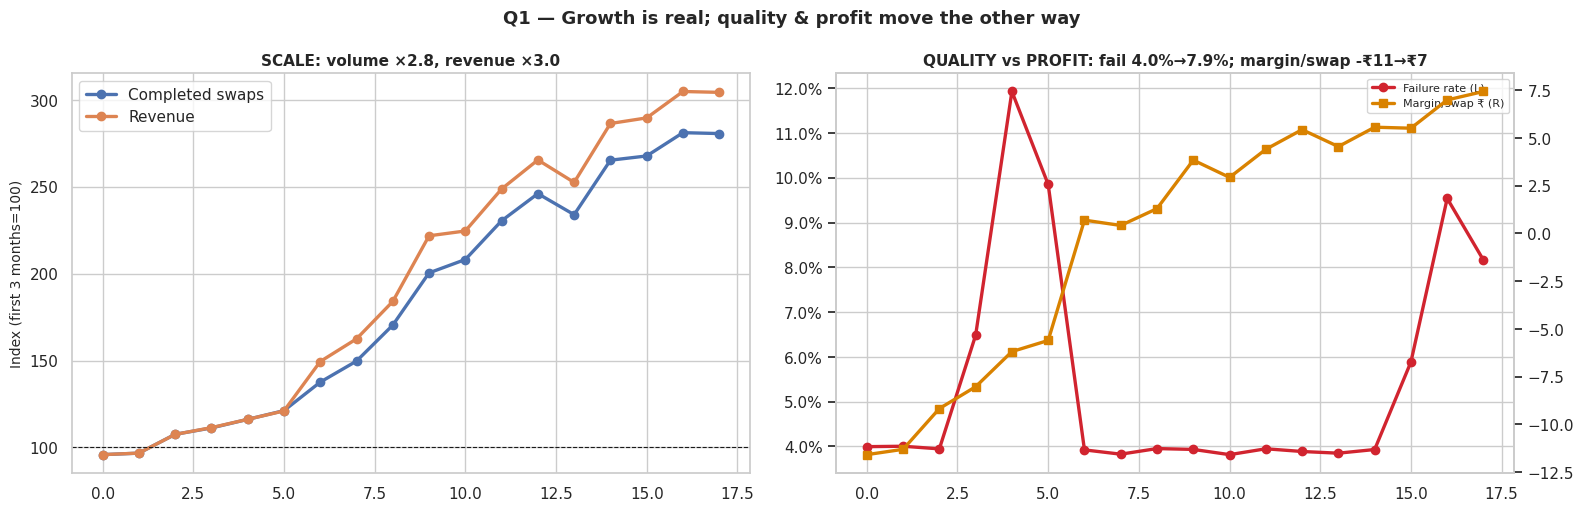

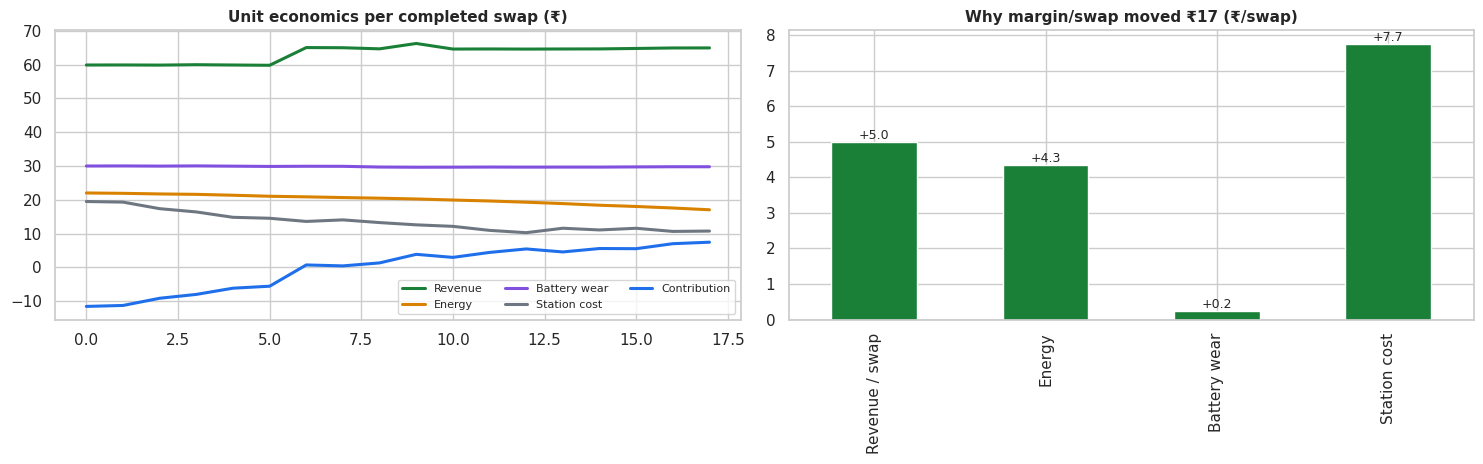

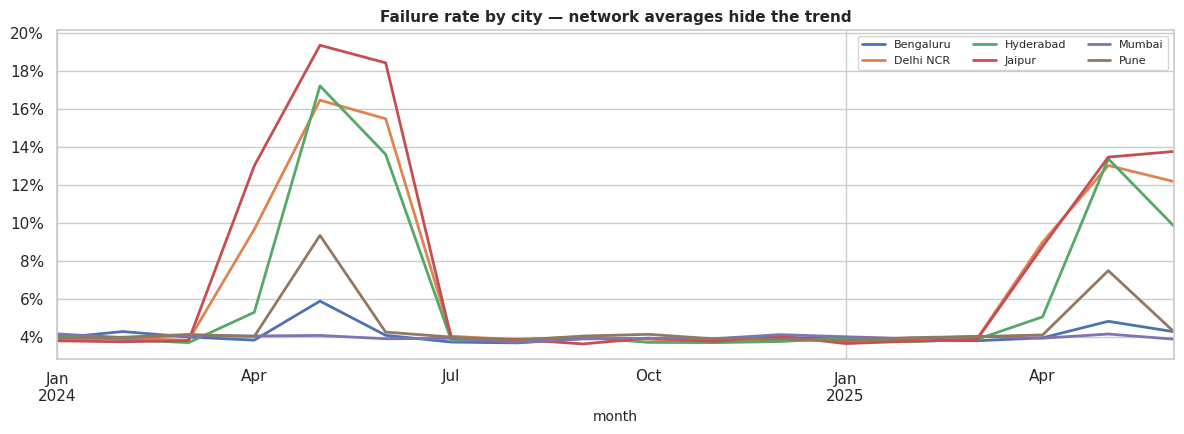

✔ Q1 network trend  (3.3s)


In [46]:
@step("Q1 network trend")
def _():
    mk = kpi_table(ev, "month"); T["monthly"] = mk
    base = mk.iloc[:3].mean(); last = mk.iloc[-3:].mean()
    M["q1"] = dict(
        swap_growth_x=float(last.completed/base.completed),
        rev_growth_x=float(last.revenue/base.revenue),
        fail_rate_first=float(base.fail_rate), fail_rate_last=float(last.fail_rate),
        margin_first=float(base.margin_per_swap), margin_last=float(last.margin_per_swap),
        rev_per_swap_first=float(base.rev_per_swap), rev_per_swap_last=float(last.rev_per_swap))
    q = M["q1"]

    fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
    idx = pd.DataFrame({"Completed swaps": mk.completed/base.completed*100,
                        "Revenue":         mk.revenue  /base.revenue  *100})
    for c, col in idx.items(): ax[0].plot(idx.index, idx[c], marker="o", lw=2.4, label=c)
    ax[0].axhline(100, color="k", lw=.8, ls="--"); ax[0].legend(loc="upper left")
    ax[0].set_ylabel("Index (first 3 months=100)")
    ax[0].set_title(f"SCALE: volume ×{q['swap_growth_x']:.1f}, revenue ×{q['rev_growth_x']:.1f}")
    ax[1].plot(mk.index, mk.fail_rate, marker="o", lw=2.4, color=C["red"], label="Failure rate (L)")
    ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.1%}")
    a2 = ax[1].twinx()
    a2.plot(mk.index, mk.margin_per_swap, marker="s", lw=2.4, color=C["orange"], label="Margin/swap ₹ (R)")
    a2.grid(False)
    h1,l1 = ax[1].get_legend_handles_labels(); h2,l2 = a2.get_legend_handles_labels()
    ax[1].legend(h1+h2, l1+l2, loc="best", fontsize=8)
    ax[1].set_title(f"QUALITY vs PROFIT: fail {pct(q['fail_rate_first'])}→{pct(q['fail_rate_last'])}; "
                    f"margin/swap {inr(q['margin_first'])}→{inr(q['margin_last'])}")
    fig.suptitle("Q1 — Growth is real; quality & profit move the other way", fontsize=13, fontweight="bold")
    fig.tight_layout(); save(fig, "03_q1_indexed_trend")

    # unit-economics bridge
    ue = pd.DataFrame({"Revenue": mk.revenue/mk.completed,
                       "Energy":  mk.energy /mk.completed,
                       "Battery wear": mk.wear/mk.completed,
                       "Station cost": mk.station_cost/mk.completed,
                       "Contribution": mk.margin_per_swap})
    b, l = ue.iloc[:3].mean(), ue.iloc[-3:].mean()
    bridge = pd.Series({"Revenue / swap":  l.Revenue - b.Revenue,
                        "Energy":         -(l.Energy - b.Energy),
                        "Battery wear":   -(l["Battery wear"] - b["Battery wear"]),
                        "Station cost":   -(l["Station cost"] - b["Station cost"])})
    M["margin_bridge"] = {k: float(v) for k,v in bridge.items()}
    M["margin_change"] = float(l.Contribution - b.Contribution)
    T["unit_economics"] = ue
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    for c, col in zip(ue.columns, [C["green"], C["orange"], C["purple"], C["grey"], C["blue"]]):
        ax[0].plot(ue.index, ue[c], lw=2.2, label=c, color=col)
    ax[0].set_title("Unit economics per completed swap (₹)"); ax[0].legend(ncol=3, fontsize=8)
    bridge.plot.bar(ax=ax[1], color=[C["green"] if v>=0 else C["red"] for v in bridge])
    ax[1].axhline(0, color="k", lw=.8)
    ax[1].set_title(f"Why margin/swap moved {inr(M['margin_change'])} (₹/swap)")
    for i,v in enumerate(bridge): ax[1].text(i, v, f"{v:+.1f}", ha="center", va="bottom" if v>=0 else "top", fontsize=9)
    fig.tight_layout(); save(fig, "04_q1_unit_economics")

    cf = kpi_table(ev, ["month","city"]).reset_index().pivot(index="month", columns="city", values="fail_rate")
    fig, ax = plt.subplots(figsize=(12, 4.5)); cf.plot(ax=ax, lw=2)
    ax.yaxis.set_major_formatter(lambda x,_: f"{x:.0%}")
    ax.set_title("Failure rate by city — network averages hide the trend"); ax.legend(ncol=3, fontsize=8)
    fig.tight_layout(); save(fig, "05_q1_fail_by_city")

## Q2 · Service failures & customer experience
**Question:** Is service quality spread evenly, or concentrated?
**Answer they will see:** ~Top 10% of stations cause ~half of all failures. Hour-of-day peaks clearly.

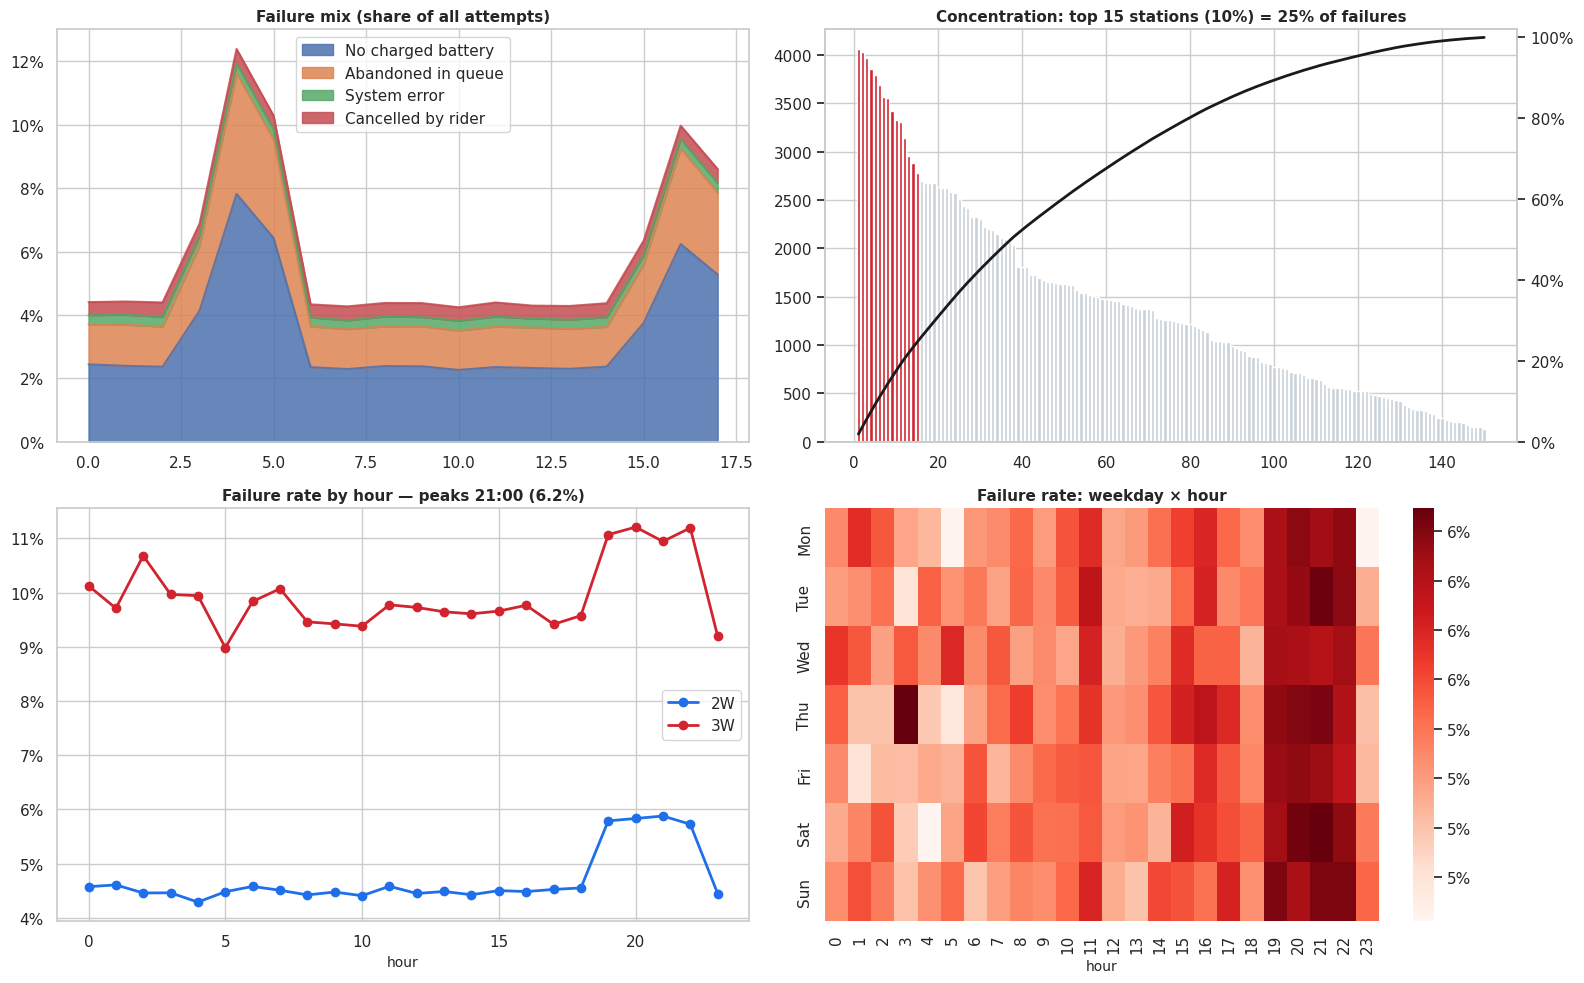

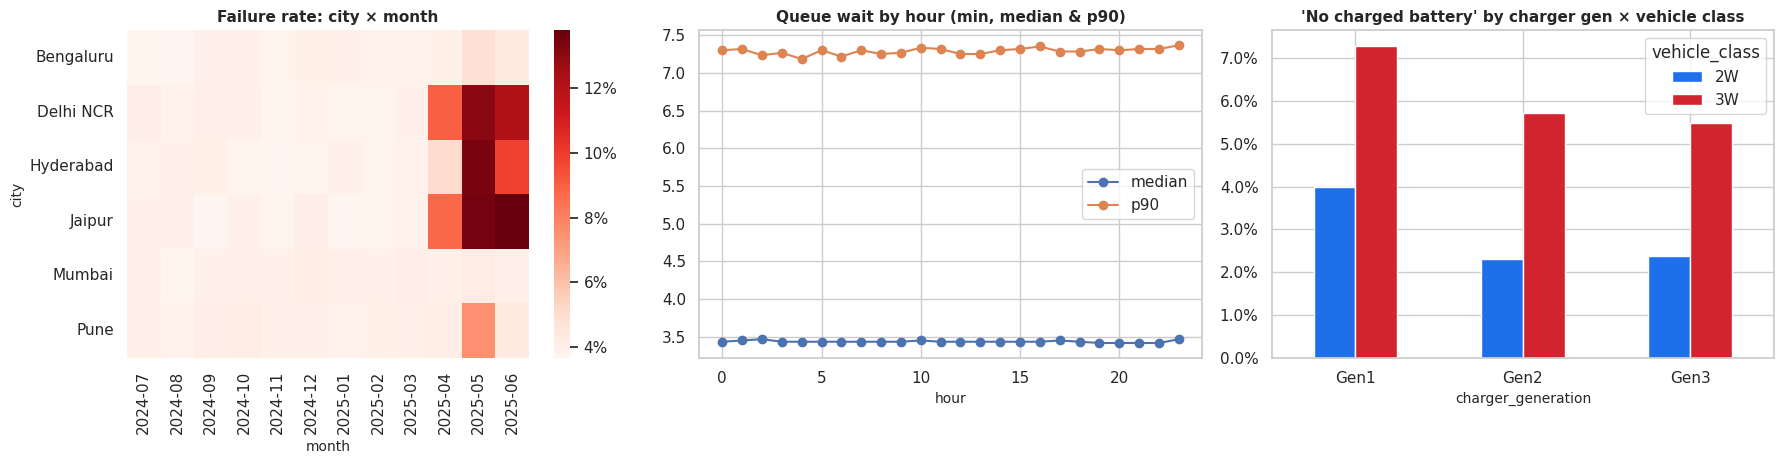

Top 15/150 stations = 24.7% of failures; 38 stations hold half
✔ Q2 failures & CX  (7.5s)


In [47]:
@step("Q2 failures & CX")
def _():
    sp = T["station_perf"].sort_values("service_fails", ascending=False)
    cum = sp.service_fails.cumsum() / sp.service_fails.sum()
    k10 = max(1, int(round(.10 * len(sp)))); share10 = float(cum.iloc[k10-1])
    share_half = int((cum < .5).sum() + 1)
    M["q2"] = dict(top10pct_stations=k10, top10pct_share=share10,
                   stations_for_half=share_half, n_stations=len(sp))
    byclass = kpi_table(ev, "vehicle_class").set_index("vehicle_class")
    M["q2"]["fail_by_class"]     = byclass.fail_rate.to_dict()
    M["q2"]["stockout_by_class"] = byclass.stockout_rate.to_dict()
    hrall = kpi_table(ev, "hour")
    M["q2"]["worst_hour"]      = int(hrall.fail_rate.idxmax())
    M["q2"]["worst_hour_rate"] = float(hrall.fail_rate.max())
    M["q2"]["best_hour_rate"]  = float(hrall.fail_rate.min())

    mix = kpi_table(ev, "month")[["stockout_rate","abandon_rate","sys_err_rate","cancel_rate"]]
    fig, ax = plt.subplots(2, 2, figsize=(16, 10))
    mix.rename(columns={"stockout_rate":"No charged battery","abandon_rate":"Abandoned in queue",
                        "sys_err_rate":"System error","cancel_rate":"Cancelled by rider"}).plot.area(ax=ax[0,0], alpha=.85)
    ax[0,0].set_title("Failure mix (share of all attempts)"); ax[0,0].yaxis.set_major_formatter(lambda x,_: f"{x:.0%}")
    x = np.arange(1, len(sp)+1)
    ax[0,1].bar(x, sp.service_fails, color=[C["red"] if i<k10 else "#c9d1d9" for i in range(len(sp))])
    a2 = ax[0,1].twinx(); a2.plot(x, cum, color="k", lw=2); a2.set_ylim(0,1.02); a2.grid(False)
    a2.yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    ax[0,1].set_title(f"Concentration: top {k10} stations ({k10/len(sp):.0%}) = {share10:.0%} of failures")
    byh = kpi_table(ev, ["hour","vehicle_class"]).reset_index()
    for vc, col in zip(["2W","3W"], [C["blue"], C["red"]]):
        d = byh[byh.vehicle_class==vc]; ax[1,0].plot(d.hour, d.fail_rate, marker="o", lw=2, label=vc, color=col)
    ax[1,0].set_title(f"Failure rate by hour — peaks {M['q2']['worst_hour']}:00 ({pct(M['q2']['worst_hour_rate'])})")
    ax[1,0].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}"); ax[1,0].legend(); ax[1,0].set_xlabel("hour")
    hm = kpi_table(ev, ["dow","hour"]).reset_index().pivot(index="dow", columns="hour", values="fail_rate")
    hm.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"][:len(hm)]
    sns.heatmap(hm, cmap="Reds", ax=ax[1,1], cbar_kws={"format":"{x:.0%}"})
    ax[1,1].set_title("Failure rate: weekday × hour")
    fig.tight_layout(); save(fig, "06_q2_failure_concentration")

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    sc = kpi_table(ev, ["city","month"]).reset_index().pivot(index="city", columns="month", values="fail_rate")
    # monthly heatmap (season field may not exist in merged frame)
    sc_plot = sc.iloc[:, -12:] if sc.shape[1] > 12 else sc
    sns.heatmap(sc_plot, cmap="Reds", ax=ax[0], cbar_kws={"format":"{x:.0%}"}, xticklabels=[str(c)[:7] for c in sc_plot.columns])
    ax[0].set_title("Failure rate: city × month")
    wq = ev.groupby("hour").wait_min.quantile([.5, .9]).unstack()
    wq.plot(ax=ax[1], marker="o"); ax[1].set_title("Queue wait by hour (min, median & p90)"); ax[1].legend(["median","p90"])
    sg = kpi_table(ev, ["charger_generation","vehicle_class"]).reset_index().pivot(
        index="charger_generation", columns="vehicle_class", values="stockout_rate")
    sg.plot.bar(ax=ax[2], color=[C["blue"], C["red"]])
    ax[2].set_title("'No charged battery' by charger gen × vehicle class")
    ax[2].yaxis.set_major_formatter(lambda y,_: f"{y:.1%}"); ax[2].tick_params(axis="x", rotation=0)
    fig.tight_layout(); save(fig, "07_q2_city_wait_stockout")
    print(f"Top {k10}/{len(sp)} stations = {share10:.1%} of failures; {share_half} stations hold half")

## Q3 · Station & geographic patterns
Four angles: attribute profile, heat→charging→stock-out chain, age & complaints, expansion waves.

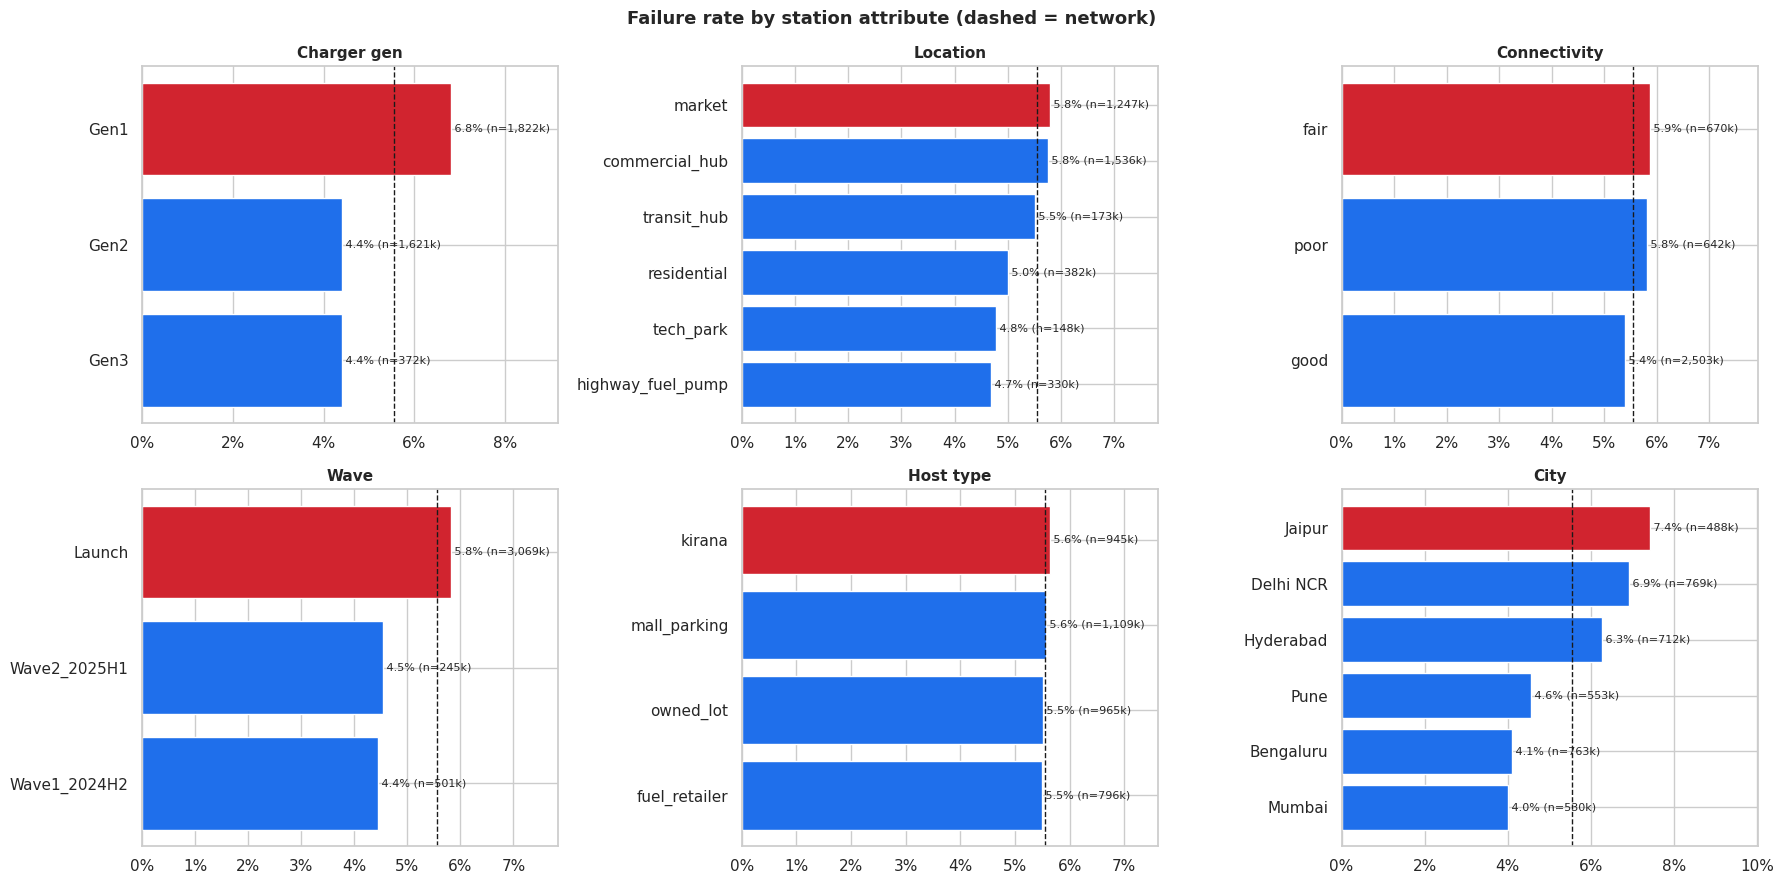

✔ Q3a station dimensions  (6.7s)


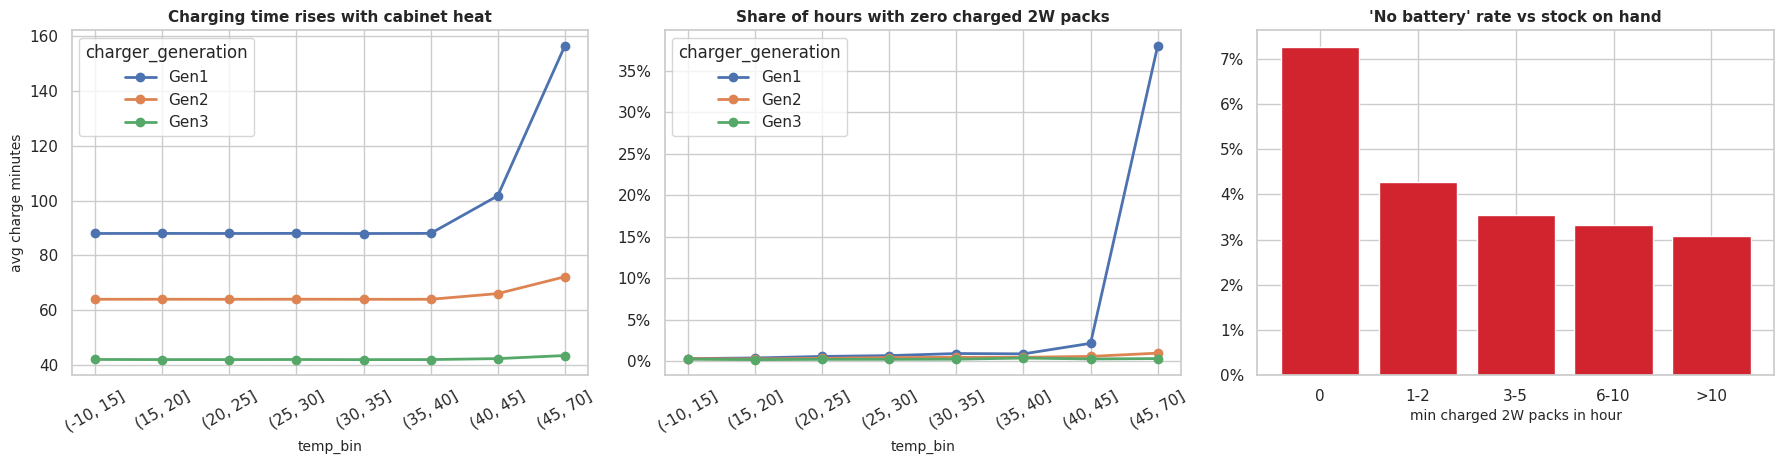

✔ Q3b heat chain  (6.9s)
age_days_station: 3,814,982 valid of 3,814,982


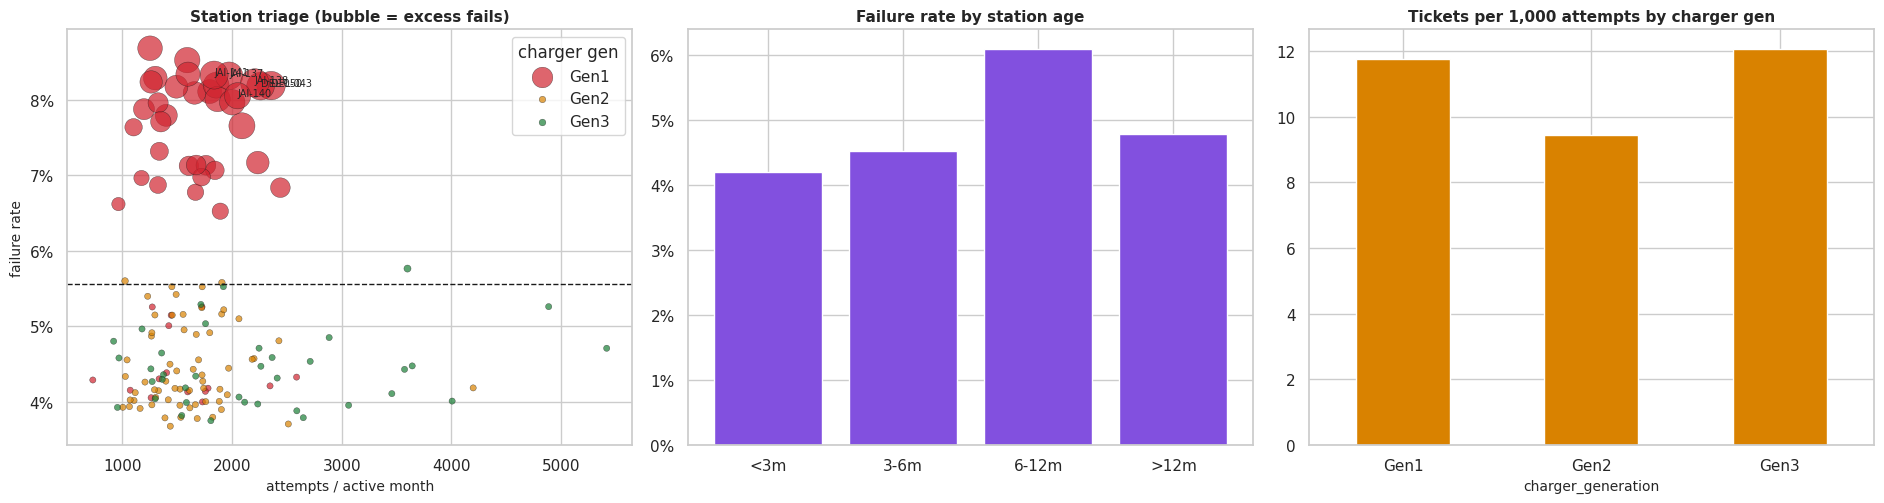

✔ Q3c station age & tickets  (3.6s)


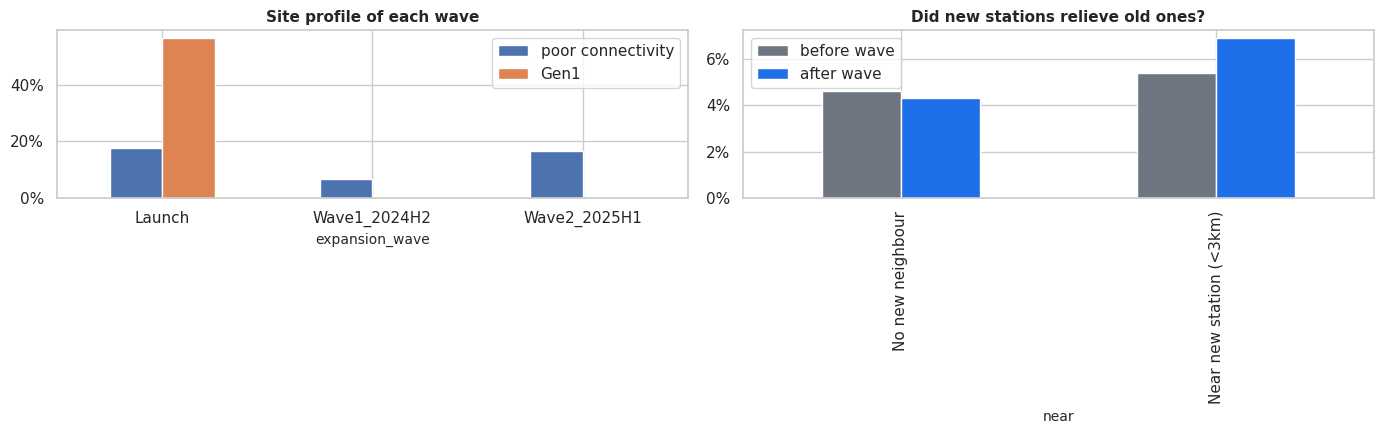

✔ Q3d expansion waves  (4.1s)


In [64]:
@step("Q3a station dimensions")
def _():
    dims = [("charger_generation","Charger gen"), ("location_type","Location"),
            ("connectivity_tier","Connectivity"), ("expansion_wave","Wave"),
            ("host_type","Host type"), ("city","City")]
    fig, ax = plt.subplots(2, 3, figsize=(18, 9))
    for a, (col, nm) in zip(ax.ravel(), dims):
        t = kpi_table(ev, col).sort_values("fail_rate")
        a.barh(t[col].astype(str), t.fail_rate,
               color=[C["red"] if v==t.fail_rate.max() else C["blue"] for v in t.fail_rate])
        for i,(v,n) in enumerate(zip(t.fail_rate, t.attempts)):
            a.text(v, i, f" {v:.1%} (n={n/1e3:,.0f}k)", va="center", fontsize=8)
        a.axvline(M["network_fail_rate"], color="k", ls="--", lw=1)
        a.set_title(nm); a.set_xlim(0, t.fail_rate.max()*1.35)
        a.xaxis.set_major_formatter(lambda x,_: f"{x:.0%}")
    fig.suptitle("Failure rate by station attribute (dashed = network)", fontsize=13, fontweight="bold")
    fig.tight_layout(); save(fig, "08_q3_station_dimensions")
    M["q3"] = dict(
        fail_by_gen=kpi_table(ev,"charger_generation").set_index("charger_generation").fail_rate.to_dict(),
        fail_by_conn=kpi_table(ev,"connectivity_tier").set_index("connectivity_tier").fail_rate.to_dict(),
        fail_by_loc=kpi_table(ev,"location_type").set_index("location_type").fail_rate.to_dict(),
        fail_by_wave=kpi_table(ev,"expansion_wave").set_index("expansion_wave").fail_rate.to_dict())

@step("Q3b heat chain")
def _():
    hs = hr.copy(); hs["station_id_str"] = hs.station_id.astype(str)
    hs = hs.merge(st[["station_id","charger_generation"]],
                  left_on="station_id_str", right_on="station_id", how="left", suffixes=("","_st"))
    ok = hs[hs.telemetry_status.eq("ok")].copy()
    ok["temp_bin"] = pd.cut(ok.cabinet_temp_c, [-10,15,20,25,30,35,40,45,70])
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    ct = ok.groupby(["temp_bin","charger_generation"], observed=True).avg_charge_minutes.mean().unstack()
    ct.plot(ax=ax[0], marker="o", lw=2); ax[0].set_ylabel("avg charge minutes")
    ax[0].set_title("Charging time rises with cabinet heat"); ax[0].tick_params(axis="x", rotation=30)
    so = ok.groupby(["temp_bin","charger_generation"], observed=True).stockout_2w.mean().unstack()
    so.plot(ax=ax[1], marker="o", lw=2); ax[1].set_title("Share of hours with zero charged 2W packs")
    ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}"); ax[1].tick_params(axis="x", rotation=30)
    e2 = ev.assign(hour_start=ev.event_ts.dt.floor("h")).groupby(
        ["station_id_str","hour_start"], observed=True).agg(
        att=("is_completed","size"), so=("is_stockout","sum")).reset_index()
    j = e2.merge(ok[["station_id_str","hour_start","charged_2w_min","charger_util","chargers_online"]],
                 on=["station_id_str","hour_start"], how="inner")
    j["stock_bin"] = pd.cut(j.charged_2w_min, [-1,0,2,5,10,100], labels=["0","1-2","3-5","6-10",">10"])
    g = j.groupby("stock_bin", observed=True).agg(att=("att","sum"), so=("so","sum"))
    g["rate"] = g.so / g.att
    ax[2].bar(g.index.astype(str), g.rate, color=C["red"])
    ax[2].set_title("'No battery' rate vs stock on hand"); ax[2].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    ax[2].set_xlabel("min charged 2W packs in hour")
    fig.tight_layout(); save(fig, "09_q3_heat_chain")
    so_h = ok[ok.stockout_2w == 1]
    M["q3"]["stockout_charger_bound_share"] = float((so_h.charger_util >= .9).mean()) if len(so_h) else np.nan
    M["q3"]["charge_min_cool"] = float(ok[ok.cabinet_temp_c < 25].avg_charge_minutes.mean())
    M["q3"]["charge_min_hot"]  = float(ok[ok.cabinet_temp_c >= 35].avg_charge_minutes.mean())

@step("Q3c station age & tickets")
def _():
    sp = T["station_perf"].copy()
    sp["months_active"] = ((DATA_END - sp.commissioned_date).dt.days / 30.4).clip(lower=1)
    sp["attempts_per_month"] = sp.attempts / sp.months_active
    fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))

    # ---- left: triage scatter (bulletproof against zero/negative sizes) ----
    try:
        max_excess = sp.excess_fails.max()
        if pd.isna(max_excess) or max_excess <= 0:
            max_excess = 1.0
        scatter_added = False
        for gname, col in zip(["Gen1","Gen2","Gen3"], [C["red"], C["orange"], C["green"]]):
            d = sp[(sp.charger_generation == gname) &
                   sp.attempts_per_month.notna() &
                   sp.fail_rate.notna() &
                   sp.excess_fails.notna()]
            if len(d) == 0:
                continue
            # KEY FIX: clip negatives so 'good' stations never produce size ≤ 0
            raw = d.excess_fails.clip(lower=0).to_numpy()
            sizes = np.clip(20 + raw / max_excess * 400, 20, 2000)
            ax[0].scatter(d.attempts_per_month.to_numpy(),
                          d.fail_rate.to_numpy(),
                          s=sizes, alpha=.7, label=gname,
                          color=col, edgecolor="k", lw=.3)
            scatter_added = True
        for sid, r_ in sp.nlargest(6, "excess_fails").iterrows():
            if pd.notna(r_.attempts_per_month) and pd.notna(r_.fail_rate):
                ax[0].annotate(str(sid).replace("STN-",""),
                               (r_.attempts_per_month, r_.fail_rate), fontsize=7)
        ax[0].axhline(M["network_fail_rate"], color="k", ls="--", lw=1)
        ax[0].set_xlabel("attempts / active month"); ax[0].set_ylabel("failure rate")
        if scatter_added:
            ax[0].legend(title="charger gen")
        ax[0].set_title("Station triage (bubble = excess fails)")
        ax[0].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    except Exception as e:
        print("triage scatter skipped:", repr(e))

    # ---- middle: age bin (already fine, kept as-is) ----
    try:
        age_series = pd.to_numeric(ev.age_days_station, errors="coerce")
        print(f"age_days_station: {age_series.notna().sum():,} valid of {len(age_series):,}")
        if age_series.notna().any():
            ev["_age_bin"] = pd.cut(age_series, [-1, 90, 180, 365, 600],
                                    labels=["<3m","3-6m","6-12m",">12m"])
            ag_df = kpi_table(ev, "_age_bin")
            if "_age_bin" in ag_df.columns and len(ag_df):
                ag = ag_df.set_index("_age_bin").fail_rate
                ax[1].bar(ag.index.astype(str), ag.values, color=C["purple"])
            ev.drop(columns="_age_bin", inplace=True)
            ax[1].set_title("Failure rate by station age")
        ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    except Exception as e:
        print("age-bin chart skipped:", repr(e))

    # ---- right: tickets ----
    try:
        tg = sp.groupby("charger_generation").agg(t=("tickets","sum"), a=("attempts","sum"))
        if len(tg) and tg.a.sum() > 0:
            (tg.t / tg.a * 1000).plot.bar(ax=ax[2], color=C["orange"])
            ax[2].set_title("Tickets per 1,000 attempts by charger gen")
            ax[2].tick_params(axis="x", rotation=0)
    except Exception as e:
        print("tickets chart skipped:", repr(e))

    fig.tight_layout(); save(fig, "10_q3_triage_age_tickets")

@step("Q3d expansion waves")
def _():
    sp = T["station_perf"].copy()
    w = sp.groupby("expansion_wave").agg(
        stations=("attempts","size"), attempts=("attempts","sum"), fails=("service_fails","sum"),
        poor_conn=("connectivity_tier", lambda x: (x=="poor").mean()),
        gen1=("charger_generation", lambda x: (x=="Gen1").mean()),
        slots2w=("slots_2w","mean"))
    w["fail_rate"] = w.fails / w.attempts
    T["wave_table"] = w
    M["q3"]["wave_spillover"] = {}
    la = sp[sp.expansion_wave == "Launch"]; nw = sp[sp.expansion_wave != "Launch"]
    if len(la) and len(nw):
        def hav(a, b):
            R = 6371.0
            p1, p2 = np.radians(a[0]), np.radians(b[0])
            dphi = p2 - p1; dl = np.radians(b[1] - a[1])
            return 2 * R * np.arcsin(np.sqrt(np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2))
        thr, near = {}, {}
        g0 = nw.commissioned_date.min()
        for sid, r_ in la.iterrows():
            d = nw.apply(lambda x: hav((r_.latitude, r_.longitude), (x.latitude, x.longitude)), axis=1)
            j = d.idxmin(); near[sid] = d.min() < 3.0
            thr[sid] = nw.loc[j, "commissioned_date"] if d.min() < 3.0 else g0
        e = ev[ev.expansion_wave.eq("Launch")][["station_id_str","event_ts","is_service_fail"]].copy()
        e["post"] = e.event_ts >= e.station_id_str.map(thr)
        e["near"] = e.station_id_str.map(near)
        r_ = e.groupby(["near","post"]).is_service_fail.mean().unstack()
        r_.index = r_.index.map({True:"Near new station (<3km)", False:"No new neighbour"})
        r_.columns = ["before wave","after wave"]
        r_["change_pp"] = (r_["after wave"] - r_["before wave"]) * 100
        M["q3"]["wave_spillover"] = r_["change_pp"].to_dict()
        fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
        w[["poor_conn","gen1"]].rename(columns={"poor_conn":"poor connectivity","gen1":"Gen1"}).plot.bar(ax=ax[0])
        ax[0].set_title("Site profile of each wave"); ax[0].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
        ax[0].tick_params(axis="x", rotation=0)
        r_[["before wave","after wave"]].plot.bar(ax=ax[1], color=[C["grey"], C["blue"]])
        ax[1].set_title("Did new stations relieve old ones?"); ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
        fig.tight_layout(); save(fig, "11_q3_expansion_waves")

## Q4 · Battery & equipment performance
Compares each lot to peers of the **same pack type** (`soh_vs_peer`) so 3W packs aren't unfairly penalised.

          packs  soh_vs_peer  low_share  degr  range_km
supplier                                               
Amptek     1307        0.318      0.000 3.056    64.560
Cellora    3555        0.334      0.000 3.045    64.164
Kyron      1638      -16.903      0.841 8.886    56.451
Flagged lots: ['KY-2407', 'KY-2408', 'KY-2409']


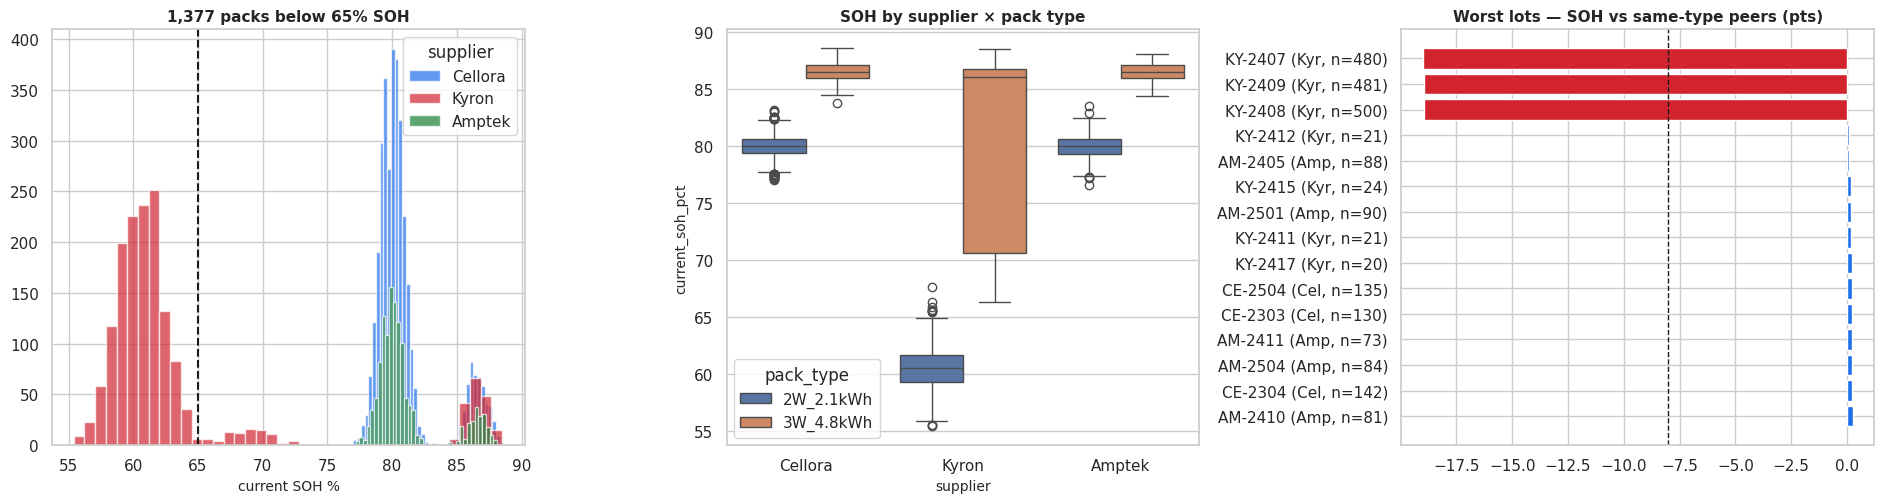

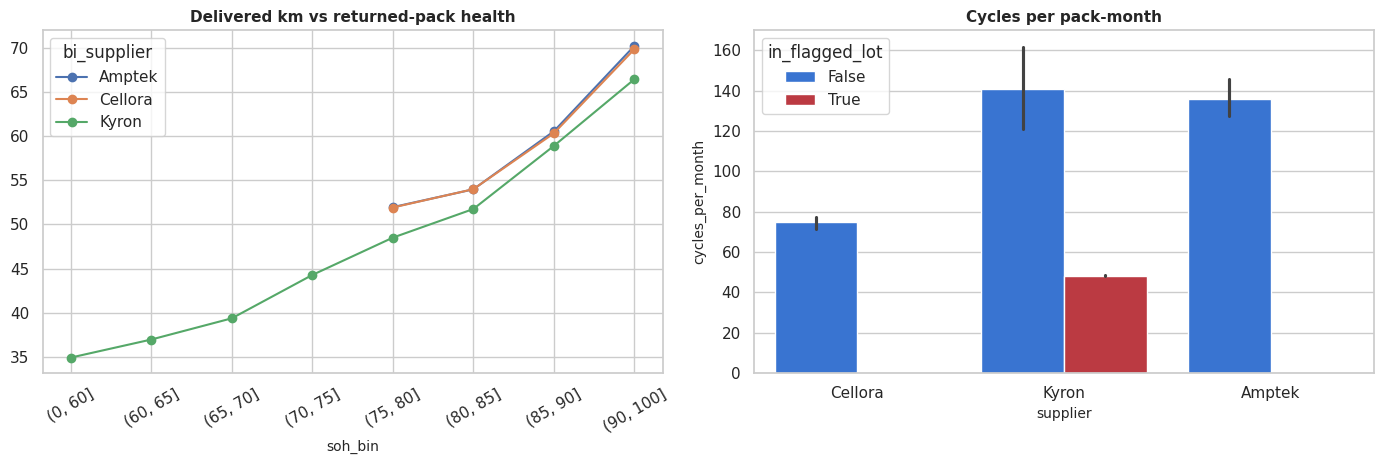

✔ Q4 batteries  (15.0s)


In [49]:
@step("Q4 batteries")
def _():
    ev_c = ev[ev.is_completed].copy()
    ev_c["bo_id"] = ev_c.battery_out_id.astype(str)
    bat = ev_c.groupby("bo_id").agg(
        cycles=("bo_id","size"),
        soh_mean_issued=("soh_out_pct","mean"),
        km_mean=("km_since_last_swap","mean")).rename_axis("battery_id").reset_index()
    bf = bt.copy(); bf["battery_id"] = bf.battery_id.astype(str)
    bf = bf.merge(bat, on="battery_id", how="left")
    bf["cycles"] = bf.cycles.fillna(0)
    bf["range_mean"] = bf.km_mean
    bf["low_soh"] = bf.current_soh_pct < LOW_SOH
    bf["retired"] = bf.retired_date.notna()
    bf["age_days"] = (DATA_END - bf.commission_date).dt.days.clip(lower=1)
    bf["cycles_per_month"] = bf.cycles / (bf.age_days / 30.4)
    bf["degr_per_100_cycles"] = np.where(bf.cycles > 20,
                                         (bf.initial_soh_pct - bf.current_soh_pct) / bf.cycles * 100, np.nan)
    bf["soh_vs_peer"] = bf.current_soh_pct - bf.groupby("pack_type").current_soh_pct.transform("median")
    bf["lot"] = bf.manufacturing_lot
    T["battery_perf"] = bf

    lot = bf.groupby(["supplier","lot"]).agg(
        packs=("battery_id","size"),
        soh_mean=("current_soh_pct","mean"),
        soh_vs_peer=("soh_vs_peer","mean"),
        low_share=("low_soh","mean"),
        cycles=("cycles","mean"),
        degr_per_100_cycles=("degr_per_100_cycles","mean"),
        cycles_per_month=("cycles_per_month","mean"),
        range_km=("range_mean","mean"),
        capital_inr=("purchase_cost_inr","sum"),
        retired_share=("retired","mean")).reset_index()
    lot["flagged"] = (lot.soh_vs_peer <= -LOT_FLAG_PTS) & (lot.packs >= 20)
    flagged_lots = set(lot.loc[lot.flagged, "lot"])
    T["lot_scorecard"] = lot.sort_values("soh_vs_peer")

    bf["in_flagged_lot"] = bf.lot.isin(flagged_lots)
    fl = bf[bf.in_flagged_lot]; ok_ = bf[~bf.in_flagged_lot]
    rng_gap = 1 - fl.range_mean.mean() / ok_.range_mean.mean() if len(fl) and ok_.range_mean.mean() > 0 else np.nan
    M["q4"] = dict(
        flagged_lots=sorted(flagged_lots),
        flagged_packs=int(len(fl)),
        flagged_pack_share=float(len(fl) / len(bf)),
        flagged_capital=float(fl.purchase_cost_inr.sum()),
        low_soh_packs=int(bf.low_soh.sum()),
        low_soh_capital=float(bf.loc[bf.low_soh, "purchase_cost_inr"].sum()),
        range_gap=float(rng_gap) if pd.notna(rng_gap) else None,
        flagged_degr=float(fl.degr_per_100_cycles.mean()) if len(fl) else None,
        other_degr=float(ok_.degr_per_100_cycles.mean()))
    sup = bf.groupby("supplier").agg(
        packs=("battery_id","size"), soh_vs_peer=("soh_vs_peer","mean"),
        low_share=("low_soh","mean"), degr=("degr_per_100_cycles","mean"),
        range_km=("range_mean","mean"))
    print(sup.round(3).to_string()); print("Flagged lots:", sorted(flagged_lots))

    fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
    for s_, col in zip(bf.supplier.unique(), [C["blue"], C["red"], C["green"], C["purple"]]):
        ax[0].hist(bf.loc[bf.supplier==s_, "current_soh_pct"], bins=40, alpha=.7, label=s_, color=col)
    ax[0].axvline(LOW_SOH, color="k", ls="--"); ax[0].legend(title="supplier")
    ax[0].set_title(f"{bf.low_soh.sum():,} packs below {LOW_SOH}% SOH"); ax[0].set_xlabel("current SOH %")
    sns.boxplot(data=bf, x="supplier", y="current_soh_pct", hue="pack_type", ax=ax[1])
    ax[1].set_title("SOH by supplier × pack type")
    show = lot[lot.packs >= 20].nsmallest(15, "soh_vs_peer").iloc[::-1]
    ax[2].barh(show.lot + " (" + show.supplier.str[:3] + ", n=" + show.packs.astype(str) + ")",
               show.soh_vs_peer, color=[C["red"] if f else C["blue"] for f in show.flagged])
    ax[2].axvline(-LOT_FLAG_PTS, color="k", ls="--", lw=1)
    ax[2].set_title("Worst lots — SOH vs same-type peers (pts)")
    fig.tight_layout(); save(fig, "12_q4_battery_health")

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
    e = ev_c.assign(soh_bin=pd.cut(ev_c.soh_in_pct, [0,60,65,70,75,80,85,90,100]))
    e["bi_supplier"] = e.battery_in_id.astype(str).map(bf.set_index("battery_id").supplier)
    rr = e.groupby(["soh_bin","bi_supplier"], observed=True).km_since_last_swap.mean().unstack()
    rr.plot(ax=ax[0], marker="o")
    ax[0].set_title("Delivered km vs returned-pack health"); ax[0].tick_params(axis="x", rotation=30)
    sns.barplot(data=bf, x="supplier", y="cycles_per_month", hue="in_flagged_lot",
                ax=ax[1], palette=[C["blue"], C["red"]])
    ax[1].set_title("Cycles per pack-month")
    fig.tight_layout(); save(fig, "13_q4_range_degradation")

## Q5 · Pricing & partner economics
Three analyses: base-price change response by plan, peak/off-peak pilot (difference-in-differences), partner-level true margin.

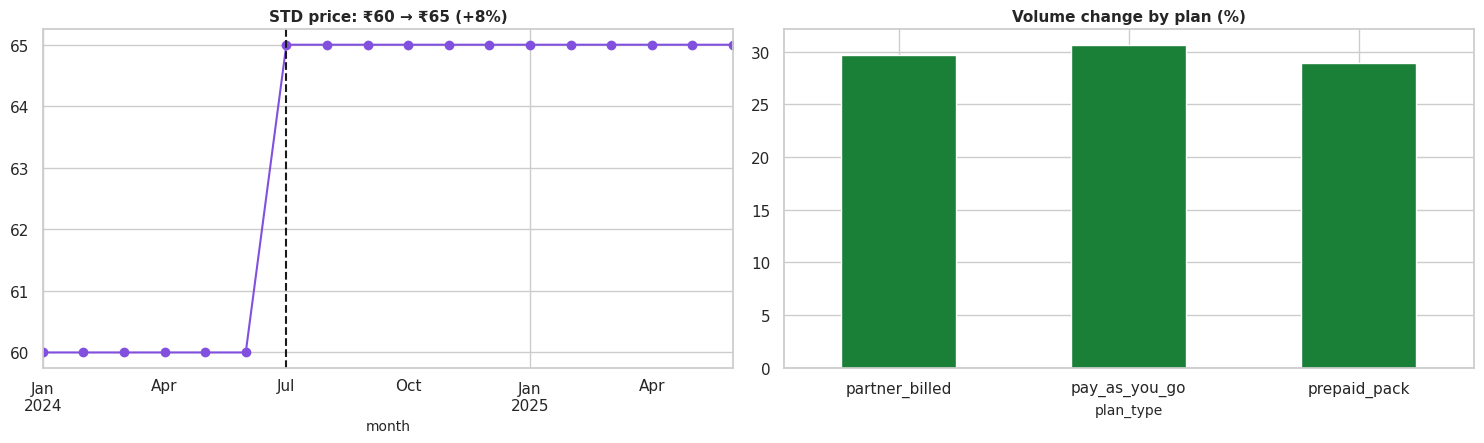

✔ Q5a base price  (3.9s)
                              peak_share  rev_per_swap  margin_per_swap  swaps_per_station_month
ALL RIDERS                        -0.031         5.392            2.232                 -178.606
Independent                       -0.025         8.028            4.987                  -25.003
Partner – NOT billable            -0.006         0.186           -2.589                  -63.818
Partner – surcharge billable      -0.045         5.716            2.122                  -89.785


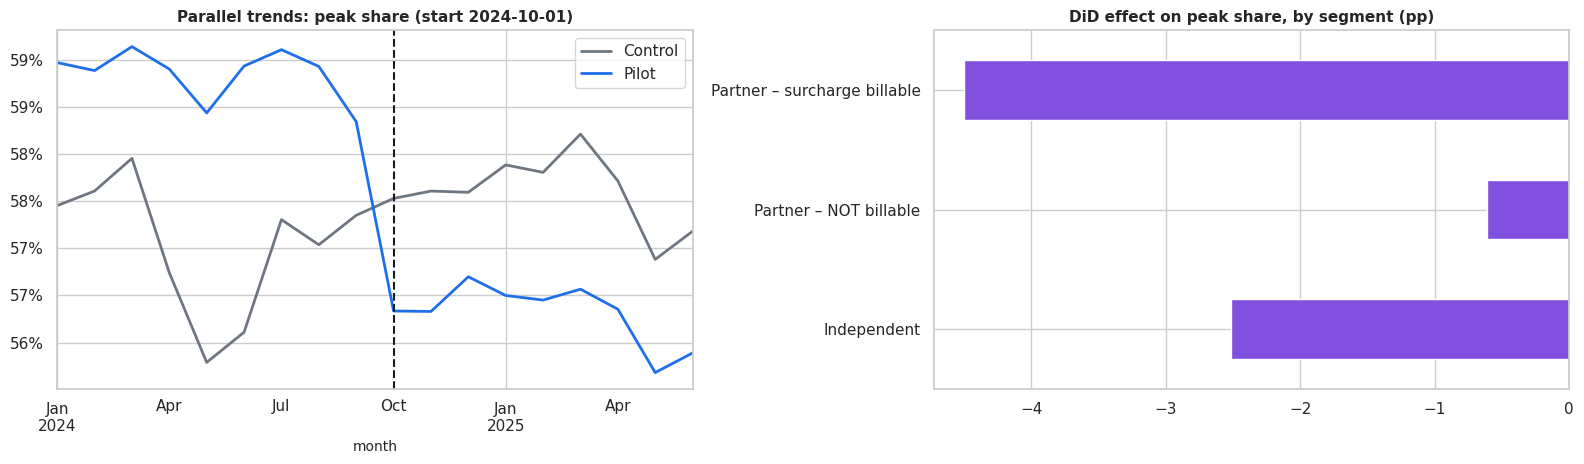

✔ Q5b peak/off-peak DiD  (11.1s)
                    completed  revenue_share  contribution_share  rev_per_swap  margin_per_swap  realised_discount  breakeven_discount
partner                                                                                                                               
Independent riders    1218521          0.363               1.528        68.210            9.078              0.000               0.110
FeastFly               516367          0.140               0.204        62.025            2.855              0.100               0.109
ZipDrop                549390          0.125              -0.579        52.070           -7.632              0.219               0.105
ParcelNest             296209          0.073              -0.103        56.515           -2.523              0.150               0.109
Swiggle Go             237632          0.061              -0.010        59.304           -0.290              0.110               0.106
CargoTuk              

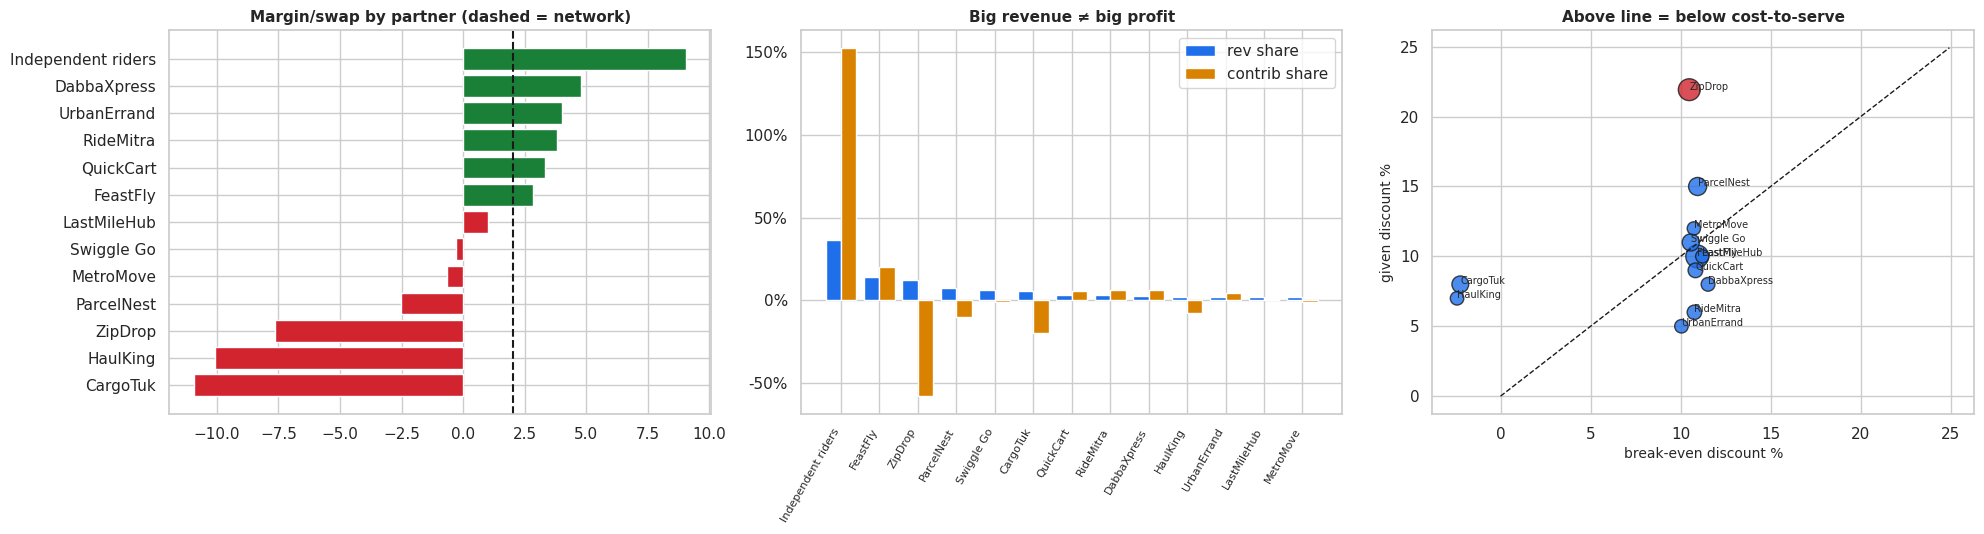

Amended: {'partner': 'ZipDrop', 'old': 12.0, 'new': 28.0, 'date': '2024-11-01', 'margin_before': -6.353886148259043, 'margin_after': -8.441521881663522, 'extra_discount_cost': 3636539.2}
✔ Q5c partner economics  (5.7s)


In [51]:
@step("Q5a base price")
def _():
    std = ev[ev.tariff_code.eq("STD") & ev.is_completed]
    pm = std.groupby("month").list_price_inr.median(); jump = pm.diff().abs()
    chg = jump.idxmax() if jump.max() > 0.5 else None
    M["q5"] = dict(price_change_month=str(chg)[:10] if chg is not None else None)
    if chg is None: print("No visible STD price change"); return
    before = pm.loc[:chg].iloc[-2] if len(pm.loc[:chg]) > 1 else pm.iloc[0]
    after  = pm.loc[chg:].iloc[0]
    M["q5"].update(price_before=float(before), price_after=float(after),
                   price_change_pct=float(after/before - 1))
    stn_pre = set(ev.loc[ev.event_ts < chg, "station_id_str"].unique())
    c = ev[ev.is_completed & ev.station_id_str.isin(stn_pre)]
    w = c.groupby(["month","plan_type"], observed=True).size().unstack()
    pre  = w[(w.index < chg) & (w.index >= chg - pd.Timedelta(days=90))].mean()
    post = w[(w.index >= chg + pd.Timedelta(days=14)) & (w.index < chg + pd.Timedelta(days=104))].mean()
    resp = (post/pre - 1).dropna()
    M["q5"]["volume_response_by_plan"] = resp.to_dict()
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
    pm.plot(ax=ax[0], marker="o", color=C["purple"]); ax[0].axvline(chg, color="k", ls="--")
    ax[0].set_title(f"STD price: ₹{before:.0f} → ₹{after:.0f} ({M['q5']['price_change_pct']:+.0%})")
    (resp*100).plot.bar(ax=ax[1], color=[C["red"] if v<0 else C["green"] for v in resp])
    ax[1].axhline(0, color="k", lw=.8)
    ax[1].set_title("Volume change by plan (%)"); ax[1].tick_params(axis="x", rotation=0)
    fig.tight_layout(); save(fig, "14_q5_base_price")

@step("Q5b peak/off-peak DiD")
def _():
    sh = ev.assign(p=ev.tariff_code.isin(["PEAK","OFFPEAK"])).groupby("city", observed=True).p.mean()
    pilot = sh[sh > .005].index.astype(str).tolist()
    if not pilot or len(pilot) == len(sh):
        print("No clear pilot split:", sh.round(4).to_dict()); return
    pk = ev[ev.tariff_code.isin(["PEAK","OFFPEAK"])]
    wk = pk.groupby("month").size(); start = wk[wk >= .2 * wk.max()].index.min()
    pp = ev[ev.city.isin(pilot) & (ev.event_ts >= start) & ev.tariff_code.isin(["STD","PEAK","OFFPEAK"])]
    hshare = (pp.tariff_code == "PEAK").groupby(pp.hour).mean()
    peak_hours = hshare[hshare > .5].index.tolist() or hshare.nlargest(4).index.tolist()
    M["q5"].update(pilot_cities=pilot, pilot_start=str(start)[:10],
                   peak_hours=[int(h) for h in peak_hours])
    d = ev.loc[ev.is_completed, ["station_id_str","city","month","hour","rev","contribution",
                                 "partner_id","peak_surcharge_billable","tariff_code","plan_type"]].copy()
    d["treat"] = d.city.astype(str).isin(pilot).astype(int)
    d["post"]  = (d.month >= start).astype(int)
    d["peak_hr"] = d.hour.isin(peak_hours)
    d["seg"] = np.select([d.partner_id.isna(), d.peak_surcharge_billable.astype(str).eq("Y")],
                         ["Independent", "Partner – surcharge billable"], "Partner – NOT billable")
    def did(df):
        g = df.groupby(["treat","post"]).agg(n=("rev","size"), peak=("peak_hr","sum"),
                                             rev=("rev","sum"), con=("contribution","sum"))
        if set(g.index) != {(0,0),(0,1),(1,0),(1,1)}: return {}
        g["peak_share"]=g.peak/g.n; g["rev_per_swap"]=g.rev/g.n; g["margin_per_swap"]=g.con/g.n
        out = {m: float((g.loc[(1,1),m]-g.loc[(1,0),m]) - (g.loc[(0,1),m]-g.loc[(0,0),m]))
               for m in ["peak_share","rev_per_swap","margin_per_swap"]}
        sw = df.groupby(["treat","post","station_id_str","month"], observed=True).size()\
              .groupby(["treat","post"]).mean().unstack()
        out["swaps_per_station_month"] = float((sw.loc[1,1]-sw.loc[1,0]) - (sw.loc[0,1]-sw.loc[0,0]))
        return out
    res = {"ALL RIDERS": did(d)}
    for s_, df in d.groupby("seg"): res[s_] = did(df)
    tab = pd.DataFrame(res).T; T["did_pilot"] = tab; M["q5"]["did"] = tab.to_dict("index")
    print(tab.round(3).to_string())

    wkp = d.groupby(["month","treat"]).peak_hr.mean().unstack()
    wkp.columns = ["Control","Pilot"]
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
    wkp.plot(ax=ax[0], lw=2, color=[C["grey"], C["blue"]]); ax[0].axvline(start, color="k", ls="--")
    ax[0].set_title(f"Parallel trends: peak share (start {str(start)[:10]})")
    ax[0].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    sub = tab.drop(index="ALL RIDERS", errors="ignore")
    if len(sub):
        (sub["peak_share"]*100).plot.barh(ax=ax[1], color=C["purple"])
        ax[1].axvline(0, color="k", lw=.8); ax[1].set_title("DiD effect on peak share, by segment (pp)")
    fig.tight_layout(); save(fig, "15_q5_pilot_did")

@step("Q5c partner economics")
def _():
    lab = ev.partner_name.astype(object).fillna("Independent riders")
    d = ev.assign(partner=lab.astype("category"),
                  list_c=np.where(ev.is_completed, ev.list_price_inr, 0.0),
                  disc_c=np.where(ev.is_completed, ev.discount_inr, 0.0))
    pt = kpi_table(d, "partner")
    x = d.groupby("partner", observed=True).agg(list_sum=("list_c","sum"), disc_sum=("disc_c","sum"))
    pt = pt.join(x, on="partner")
    pt["realised_discount"]  = pt.disc_sum / pt.list_sum.replace(0, np.nan)
    pt["cost_per_swap"]      = (pt.energy + pt.wear + pt.station_cost) / pt.completed.clip(lower=1)
    pt["list_per_swap"]      = pt.list_sum / pt.completed.clip(lower=1)
    pt["breakeven_discount"] = 1 - pt.cost_per_swap / pt.list_per_swap.replace(0, np.nan)
    pt["revenue_share"]      = pt.revenue / pt.revenue.sum()
    pt["contribution_share"] = pt.contribution / pt.contribution.sum()
    meta = fp.set_index("partner_name")[["partner_segment","contract_type","discount_pct",
                                          "amendment_date","discount_pct_after_amendment",
                                          "peak_surcharge_billable","payment_terms_days"]]
    pt["partner_name"] = pt.partner
    pt = pt.merge(meta, left_on="partner", right_index=True, how="left")
    pt = pt.set_index("partner").sort_values("revenue", ascending=False)
    T["partner_economics"] = pt
    big = pt.drop(index="Independent riders", errors="ignore").index[0]
    M["q5"]["largest_partner"] = dict(
        name=big, revenue_share=float(pt.loc[big,"revenue_share"]),
        contribution_share=float(pt.loc[big,"contribution_share"]),
        margin_per_swap=float(pt.loc[big,"margin_per_swap"]),
        realised_discount=float(pt.loc[big,"realised_discount"]),
        breakeven_discount=float(pt.loc[big,"breakeven_discount"]),
        network_margin=M["network_margin_per_swap"])
    print(pt[["completed","revenue_share","contribution_share","rev_per_swap",
              "margin_per_swap","realised_discount","breakeven_discount"]].round(3).to_string())

    fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
    p2 = pt.sort_values("margin_per_swap")
    ax[0].barh(p2.index.astype(str), p2.margin_per_swap,
               color=[C["red"] if v < M["network_margin_per_swap"] else C["green"] for v in p2.margin_per_swap])
    ax[0].axvline(M["network_margin_per_swap"], color="k", ls="--")
    ax[0].set_title("Margin/swap by partner (dashed = network)")
    xx = np.arange(len(pt)); w_ = .4
    ax[1].bar(xx - w_/2, pt.revenue_share, w_, label="rev share", color=C["blue"])
    ax[1].bar(xx + w_/2, pt.contribution_share, w_, label="contrib share", color=C["orange"])
    ax[1].set_xticks(xx); ax[1].set_xticklabels(pt.index.astype(str), rotation=60, ha="right", fontsize=8)
    ax[1].legend(); ax[1].set_title("Big revenue ≠ big profit")
    ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    pp_ = pt.drop(index="Independent riders", errors="ignore").dropna(subset=["breakeven_discount","realised_discount"])
    if len(pp_):
        ax[2].scatter(pp_.breakeven_discount*100, pp_.realised_discount*100,
                      s=60+pp_.revenue_share*1500,
                      c=[C["red"] if pd.notna(a) else C["blue"] for a in pp_.amendment_date],
                      alpha=.8, edgecolor="k")
        lim = [0, max(pp_.breakeven_discount.max(), pp_.realised_discount.max())*100+3]
        ax[2].plot(lim, lim, "k--", lw=1)
        ax[2].set_xlabel("break-even discount %"); ax[2].set_ylabel("given discount %")
        ax[2].set_title("Above line = below cost-to-serve")
        for n_, r_ in pp_.iterrows():
            ax[2].annotate(str(n_)[:14], (r_.breakeven_discount*100, r_.realised_discount*100), fontsize=7)
    fig.tight_layout(); save(fig, "16_q5_partner_economics")

    am = fp[fp.amendment_date.notna() & fp.discount_pct_after_amendment.notna()]
    if len(am):
        r0 = am.iloc[0]; e = ev[ev.partner_id.eq(r0.partner_id) & ev.is_completed]
        if len(e):
            e = e.assign(post=e.event_ts >= r0.amendment_date)
            g = e.groupby("post").agg(swaps=("rev","size"), rev=("rev","sum"),
                                       con=("contribution","sum"),
                                       lst=("list_price_inr","sum"))
            g["margin_per_swap"] = g.con/g.swaps
            M["q5"]["amended"] = dict(
                partner=str(r0.partner_name),
                old=float(r0.discount_pct), new=float(r0.discount_pct_after_amendment),
                date=str(r0.amendment_date)[:10],
                margin_before=float(g.margin_per_swap.get(False, np.nan)),
                margin_after=float(g.margin_per_swap.get(True, np.nan)),
                extra_discount_cost=float(g.lst.get(True,0)*(r0.discount_pct_after_amendment - r0.discount_pct)/100))
            print("Amended:", M["q5"]["amended"])

## Q6 · Root cause of new-rider churn
**Definition:** retained = any completed swap between day 30–60 after first attempt.
**Method:** retention curves → RandomForest + permutation importance on factor *groups* → primary vs secondary.

riders scored: 17,444 of 19,941 | 30-60d retention 86.9%


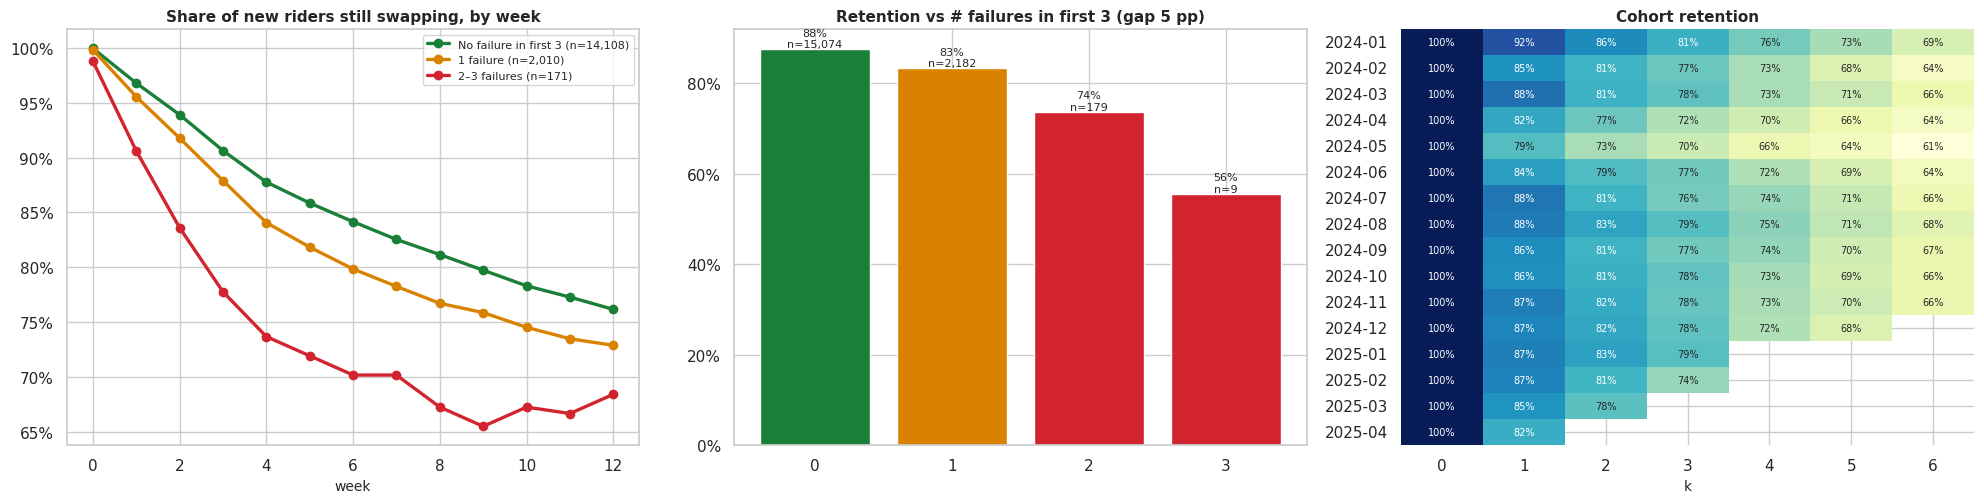

RF AUC 0.578
                           auc_drop    sd        role
Battery condition / range     0.046 0.007     PRIMARY
Service quality (first 3)     0.015 0.006   secondary
Station quality               0.003 0.005  negligible
Price & discount              0.001 0.001  negligible
Acquisition & plan           -0.000 0.003  negligible
Rider profile                -0.002 0.007  negligible


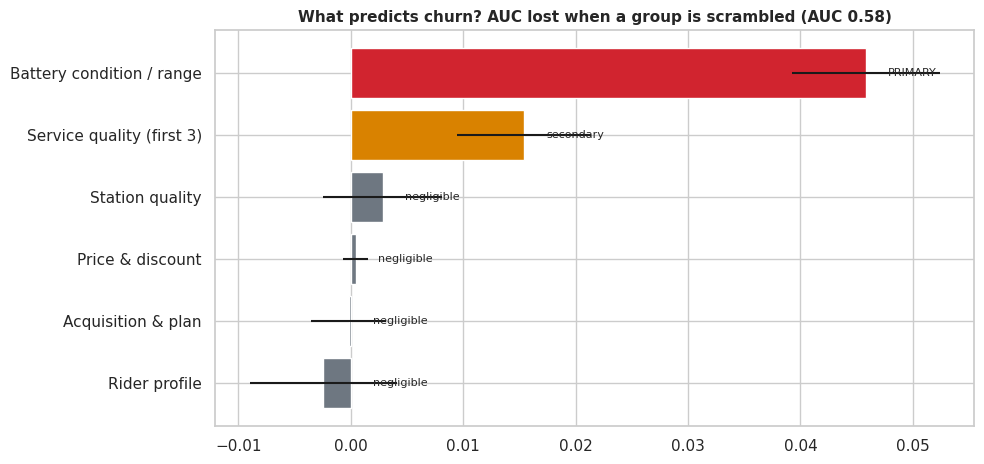

✔ Q6 retention drivers  (17.5s)


In [52]:
@step("Q6 retention drivers")
def _():
    cols = ["rider_id_str","event_ts","is_completed","is_service_fail","is_stockout",
            "wait_min","station_id_str","discount_ratio","soh_out_pct",
            "km_since_last_swap","tariff_code"]
    e = ev[cols].sort_values(["rider_id_str","event_ts"]).reset_index(drop=True)
    g = e.groupby("rider_id_str")
    e["n"] = g.cumcount()
    e["days"] = (e.event_ts - g.event_ts.transform("min")).dt.total_seconds()/86400
    e["is_peak_t"] = e.tariff_code.eq("PEAK")
    f3 = e[e.n < 3].groupby("rider_id_str").agg(
        n3=("n","size"), fails3=("is_service_fail","sum"), stockouts3=("is_stockout","sum"),
        wait3=("wait_min","mean"), disc3=("discount_ratio","mean"),
        soh3=("soh_out_pct","mean"), km3=("km_since_last_swap","mean"), peak3=("is_peak_t","mean"))
    first = e[e.n == 0].set_index("rider_id_str")[["event_ts","station_id_str","is_service_fail"]]
    first.columns = ["first_ts","first_station","first_attempt_failed"]
    rf = f3.join(first)
    rf["first_station"] = rf.first_station.astype(str)
    rf["first_attempt_failed"] = rf.first_attempt_failed.astype(int)
    late = set(e.loc[e.is_completed & (e.days >= RET_LO) & (e.days < RET_HI), "rider_id_str"].unique())
    rf["retained"] = rf.index.isin(late).astype(int)
    rf["eligible"] = rf.first_ts <= DATA_END - pd.Timedelta(days=RET_HI)
    rf["first_station_fail"] = rf.first_station.map(T["station_perf"].fail_rate)
    r2 = rd.set_index("rider_id"); r2.index = r2.index.astype(str)
    rf = rf.join(r2[["vehicle_class","plan_type","signup_channel","home_city","age_band","kyc_verified","partner_id"]])
    rf["kyc_verified"] = rf.kyc_verified.astype(int)
    rf["is_partner"]   = rf.partner_id.notna().astype(int)
    rf["first3_group"] = pd.cut(rf.fails3, [-1,0,1,3],
                                labels=["No failure in first 3","1 failure","2–3 failures"])
    rf["cohort"] = rf.first_ts.dt.to_period("M").dt.to_timestamp()
    T["rider_features"] = rf
    el = rf[rf.eligible].copy()
    print(f"riders scored: {len(el):,} of {len(rf):,} | 30-60d retention {el.retained.mean():.1%}")
    clean = el[el.fails3 == 0].retained.mean()
    hurt  = el[el.fails3 >= 1].retained.mean()
    M["q6"] = dict(
        riders_scored=int(len(el)), retention=float(el.retained.mean()),
        ret_no_fail=float(clean), ret_any_fail=float(hurt),
        gap_pp=float((clean-hurt)*100),
        n_exposed=int((el.fails3 >= 1).sum()),
        ret_by_fails={str(k): float(v) for k,v in el.groupby("fails3").retained.mean().items()},
        first_attempt_failed_gap_pp=float((el[el.first_attempt_failed==0].retained.mean()
                                            - el[el.first_attempt_failed==1].retained.mean())*100))

    # retention curves
    ep = rf[rf.first_ts <= DATA_END - pd.Timedelta(days=91)].index
    cw = (e[e.is_completed & (e.days < 91)]
          .assign(wk=lambda d: (d.days // 7).astype(int))
          .groupby(["rider_id_str","wk"]).size().unstack(fill_value=0)
          .gt(0).reindex(index=ep, columns=range(13), fill_value=False))
    curve = cw.groupby(rf.loc[ep, "first3_group"].astype(str).values).mean().T

    fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
    for c_, col in zip(["No failure in first 3","1 failure","2–3 failures"],
                       [C["green"], C["orange"], C["red"]]):
        if c_ in curve:
            ax[0].plot(curve.index, curve[c_], marker="o", lw=2.4, color=col,
                       label=f"{c_} (n={int((rf.loc[ep,'first3_group'].astype(str)==c_).sum()):,})")
    ax[0].set_title("Share of new riders still swapping, by week")
    ax[0].set_xlabel("week"); ax[0].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}"); ax[0].legend(fontsize=8)
    rb = el.groupby("fails3").retained.agg(["mean","size"])
    ax[1].bar(rb.index.astype(str), rb["mean"],
              color=[C["green"], C["orange"], C["red"], C["red"]][:len(rb)])
    for i,(m_, n_) in enumerate(zip(rb["mean"], rb["size"])):
        ax[1].text(i, m_, f"{m_:.0%}\nn={n_:,}", ha="center", va="bottom", fontsize=8)
    ax[1].set_title(f"Retention vs # failures in first 3 (gap {M['q6']['gap_pp']:.0f} pp)")
    ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    cm = (e[e.is_completed & (e.days < 210)].assign(k=lambda d: (d.days // 30).astype(int))
          .groupby(["rider_id_str","k"]).size().unstack(fill_value=0).gt(0)
          .reindex(index=rf.index, columns=range(7), fill_value=False))
    coh = cm.groupby(rf.cohort.values).mean()
    for c_ in coh.index:
        for k in coh.columns:
            if pd.Timestamp(c_) + pd.DateOffset(months=1) + pd.Timedelta(days=30*(k+1)) > DATA_END:
                coh.loc[c_, k] = np.nan
    coh = coh.dropna(how="all")
    if len(coh):
        sns.heatmap(coh, cmap="YlGnBu", annot=True, fmt=".0%", ax=ax[2], cbar=False, annot_kws={"size":7})
        ax[2].set_title("Cohort retention"); ax[2].set_yticklabels([str(i)[:7] for i in coh.index], rotation=0)
    fig.tight_layout(); save(fig, "17_q6_retention_curves")

    # Model + grouped permutation importance
    from sklearn.model_selection import train_test_split
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.metrics import roc_auc_score
    GROUPS = {
        "Service quality (first 3)": ["fails3","stockouts3","wait3","first_attempt_failed"],
        "Station quality":           ["first_station_fail"],
        "Price & discount":          ["disc3","peak3"],
        "Battery condition / range": ["soh3","km3"],
        "Acquisition & plan":        ["signup_channel","plan_type","is_partner"],
        "Rider profile":             ["vehicle_class","age_band","kyc_verified","home_city"]}
    feats = [f for fs in GROUPS.values() for f in fs]
    X = el[feats].copy(); y = el.retained.values
    cat = [c for c in feats if str(X[c].dtype) in ("object","category","string")]
    num = [c for c in feats if c not in cat]
    for c in cat: X[c] = X[c].astype(str)
    try: ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError: ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    pre = ColumnTransformer([
        ("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
        ("c", ohe, cat)])
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=42, stratify=y)
    rfm = Pipeline([("p", pre), ("m", RandomForestClassifier(300, min_samples_leaf=20,
                                                             class_weight="balanced",
                                                             n_jobs=-1, random_state=42))]).fit(Xtr, ytr)
    base_auc = roc_auc_score(yte, rfm.predict_proba(Xte)[:,1])
    rng_ = np.random.default_rng(0); drops = {}
    for gname, fs in GROUPS.items():
        d_ = []
        for _ in range(6):
            Xp = Xte.copy(); perm = rng_.permutation(len(Xp)); Xp[fs] = Xte[fs].values[perm]
            d_.append(base_auc - roc_auc_score(yte, rfm.predict_proba(Xp)[:,1]))
        drops[gname] = (np.mean(d_), np.std(d_))
    imp = pd.DataFrame(drops, index=["auc_drop","sd"]).T.sort_values("auc_drop", ascending=False)
    top = imp.auc_drop.max()
    imp["role"] = np.where((imp.auc_drop >= .4*top) & (imp.auc_drop >= .01), "PRIMARY",
                          np.where(imp.auc_drop >= .003, "secondary", "negligible"))
    T["retention_drivers"] = imp
    M["q6"].update(model_auc=float(base_auc),
                   drivers=imp.reset_index().rename(columns={"index":"group"}).to_dict("records"))
    print(f"RF AUC {base_auc:.3f}"); print(imp.round(4).to_string())

    cols_ = {"PRIMARY": C["red"], "secondary": C["orange"], "negligible": C["grey"]}
    fig, ax = plt.subplots(figsize=(10, 4.8))
    im = imp.iloc[::-1]
    ax.barh(im.index, im.auc_drop, xerr=im.sd, color=[cols_[r] for r in im.role])
    ax.set_title(f"What predicts churn? AUC lost when a group is scrambled (AUC {base_auc:.2f})")
    for i,(v,r_) in enumerate(zip(im.auc_drop, im.role)):
        ax.text(max(v,0)+.002, i, r_, va="center", fontsize=8)
    fig.tight_layout(); save(fig, "18_q6_drivers")

    el["flag2"] = el.fails3 >= 2
    churners = el[el.retained == 0]
    M["q6"]["early_warning"] = dict(
        rule="≥2 service failures in first 3 attempts",
        flagged_share_of_riders=float(el.flag2.mean()),
        share_of_churners_caught=float(churners.flag2.mean()),
        precision=float(1 - el[el.flag2].retained.mean()) if el.flag2.any() else np.nan)

## 11 · Anomalies worth flagging
Extreme-failure stations (z-score > 3), flagged battery lots, firmware bug visualisation, offline-sync share.

                            type          id       metric   value                  note
        station: extreme failure STN-DEL-033      z-score  18.000 fail 7.8%, Gen1, good
        station: extreme failure STN-DEL-035      z-score  17.400 fail 7.9%, Gen1, good
        station: extreme failure STN-DEL-036      z-score  21.000 fail 8.1%, Gen1, good
        station: extreme failure STN-DEL-037      z-score  24.000 fail 8.7%, Gen1, good
        station: extreme failure STN-DEL-038      z-score  12.800 fail 7.3%, Gen1, good
        station: extreme failure STN-DEL-039      z-score  19.700 fail 8.1%, Gen1, fair
        station: extreme failure STN-DEL-040      z-score  23.100 fail 8.2%, Gen1, fair
        station: extreme failure STN-DEL-043      z-score  25.600 fail 8.2%, Gen1, poor
        station: extreme failure STN-DEL-045      z-score  21.400 fail 8.3%, Gen1, good
        station: extreme failure STN-DEL-047      z-score  21.900 fail 8.0%, Gen1, good
        station: extreme failure

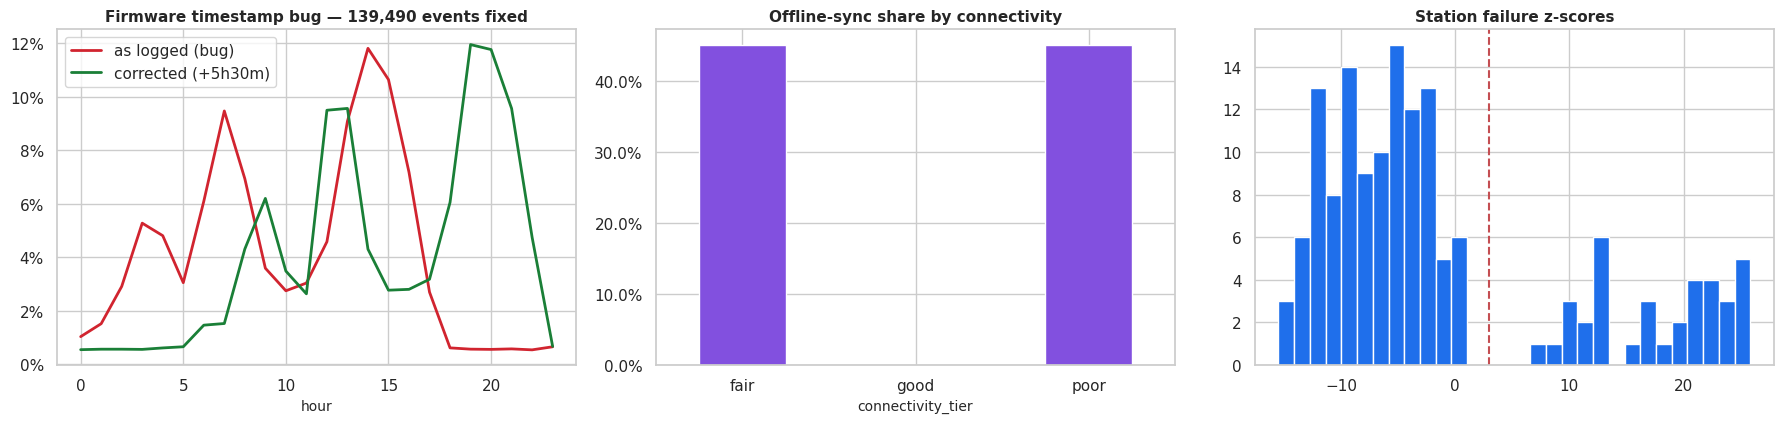

✔ Anomalies  (1.2s)


In [54]:
@step("Anomalies")
def _():
    sp = T["station_perf"]; p = M["network_fail_rate"]; rows = []
    z = (sp.service_fails - sp.attempts*p) / np.sqrt(sp.attempts*p*(1-p))
    for sid, v in z[z > 3].items():
        rows.append(dict(type="station: extreme failure", id=sid, metric="z-score",
                         value=round(v,1),
                         note=f"fail {sp.loc[sid,'fail_rate']:.1%}, {sp.loc[sid,'charger_generation']}, {sp.loc[sid,'connectivity_tier']}"))
    for l_ in M.get("q4", {}).get("flagged_lots", []):
        rows.append(dict(type="battery lot: unusual degradation", id=l_,
                         metric="SOH vs peers",
                         value=round(T["lot_scorecard"].set_index("lot").loc[l_, "soh_vs_peer"], 1),
                         note="below same-type peers"))
    an = pd.DataFrame(rows); T["anomalies"] = an
    print(an.to_string(index=False) if len(an) else "none")

    fx = ev[ev.ts_fixed]
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
    if len(fx):
        raw_h = (fx.event_ts - FW_SHIFT).dt.hour; fixed_h = fx.event_ts.dt.hour
        pd.DataFrame({"as logged (bug)": raw_h.value_counts(normalize=True).sort_index(),
                      "corrected (+5h30m)": fixed_h.value_counts(normalize=True).sort_index()}
                    ).plot(ax=ax[0], lw=2, color=[C["red"], C["green"]])
        ax[0].set_title(f"Firmware timestamp bug — {len(fx):,} events fixed")
        ax[0].set_xlabel("hour"); ax[0].yaxis.set_major_formatter(lambda y,_: f"{y:.0%}")
    ct = ev.groupby("connectivity_tier", observed=True).sync_mode.apply(lambda s: (s=="offline_batch").mean())
    ct.plot.bar(ax=ax[1], color=C["purple"]); ax[1].set_title("Offline-sync share by connectivity")
    ax[1].yaxis.set_major_formatter(lambda y,_: f"{y:.1%}"); ax[1].tick_params(axis="x", rotation=0)
    ax[2].hist(z, bins=30, color=C["blue"]); ax[2].axvline(3, color="r", ls="--")
    ax[2].set_title("Station failure z-scores")
    fig.tight_layout(); save(fig, "19_anomalies")

## 12 · Business impact in ₹
Every number is derived from data + explicit CONFIG assumptions (RECOVERY_RATE, wear cost per cycle). Leadership can challenge the inputs.

                           metric    value
 Revenue lost to failures (18 mo) ₹1.42 Cr
  Annualised (last 3 mo run-rate) ₹2.04 Cr
              …in top 15 stations    23.7%
      Recoverable at 60% recovery ₹28.99 L
                Annual churn cost ₹23.65 L
  Battery capital in flagged lots ₹4.95 Cr
Battery capital < end-of-life SOH ₹4.40 Cr
  Amended contract extra discount ₹36.37 L


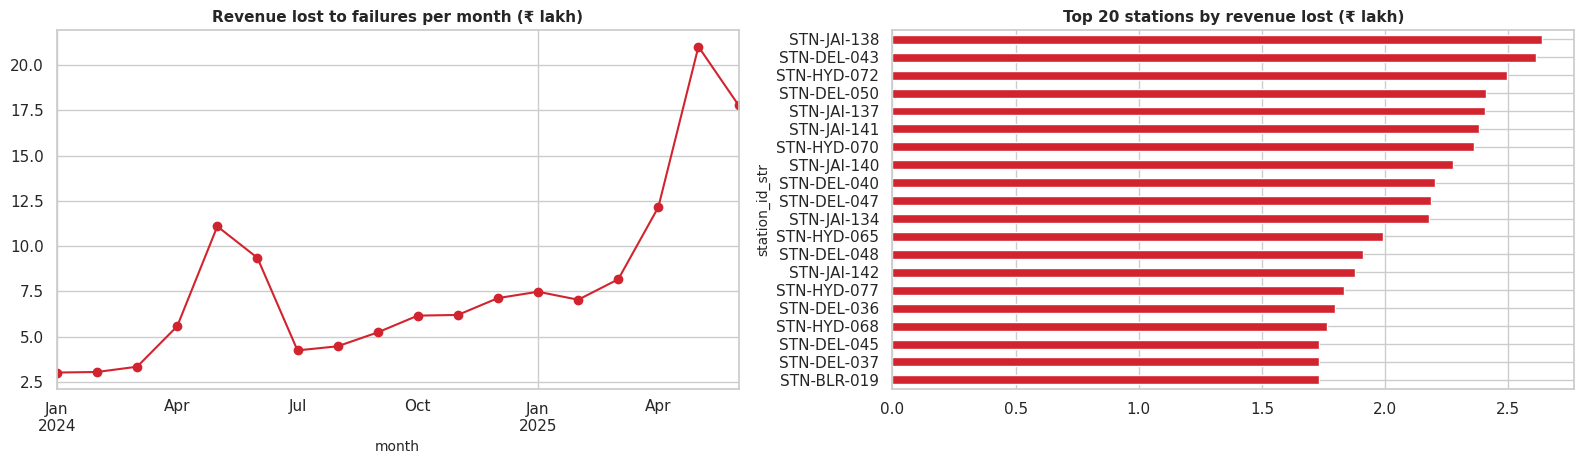

✔ Business impact  (7.0s)
                     city               zone   location_type charger_generation connectivity_tier expansion_wave  attempts  fail_rate  stockout_rate  abandon_rate  sys_err_rate  p90_wait_min  tickets_per_1k  excess_fails  lost_revenue                                                                  diagnosis
station_id_str                                                                                                                                                                                                                                                                                                       
STN-JAI-138        Jaipur  JAI-Malviya Nagar          market               Gen1              poor         Launch     48945      0.082          0.054         0.025         0.003         7.433          13.771     1,306.045   263,502.832  stock-outs → more inventory / faster turnaround (Gen1); poor connectivity
STN-DEL-043     Delhi NCR           DEL-East

In [55]:
@step("Business impact")
def _():
    sp = T["station_perf"]; net_rev = M["network_rev_per_swap"]
    avg = (ev[ev.is_completed].groupby(["station_id_str","vehicle_class"], observed=True)
           .rev.mean().reset_index())
    f = ev.loc[ev.is_service_fail, ["station_id_str","vehicle_class","month"]].copy()
    f = f.merge(avg, on=["station_id_str","vehicle_class"], how="left")
    f["rev"] = f.rev.fillna(net_rev)
    lost_m = f.groupby("month").rev.sum()
    lost_s = f.groupby("station_id_str").rev.sum().sort_values(ascending=False)
    run_rate = float(lost_m.iloc[-3:].mean() * 12)
    topn = lost_s.head(TOP_N_FIX)
    imp = dict(
        lost_revenue_total=float(lost_m.sum()),
        lost_revenue_annualised=run_rate,
        topN_share=float(topn.sum()/lost_s.sum()),
        topN=TOP_N_FIX,
        recoverable_annual=float(run_rate * topn.sum()/lost_s.sum() * RECOVERY_RATE))
    q6 = M.get("q6", {})
    if q6:
        rm = ev[ev.is_completed].groupby(["rider_id_str","month"], observed=True).ngroups
        rev_per_rider_month = M["revenue"] / max(rm, 1)
        excess = q6["n_exposed"] * max(q6["ret_no_fail"] - q6["ret_any_fail"], 0)
        imp.update(
            rev_per_active_rider_month=float(rev_per_rider_month),
            excess_riders_lost=float(excess),
            churn_cost_annual=float(excess * rev_per_rider_month * 12),
            avg_retained_months_assumed=12)
    q4 = M.get("q4", {})
    imp["battery_capital_flagged"] = q4.get("flagged_capital", np.nan)
    imp["battery_capital_low_soh"] = q4.get("low_soh_capital", np.nan)
    am = M.get("q5", {}).get("amended")
    if am: imp["amended_contract_extra_discount"] = am["extra_discount_cost"]
    M["impact"] = imp; T["lost_by_station"] = lost_s
    tbl = pd.DataFrame({
        "metric": ["Revenue lost to failures (18 mo)",
                   "Annualised (last 3 mo run-rate)",
                   f"…in top {TOP_N_FIX} stations",
                   f"Recoverable at {RECOVERY_RATE:.0%} recovery",
                   "Annual churn cost",
                   "Battery capital in flagged lots",
                   "Battery capital < end-of-life SOH",
                   "Amended contract extra discount"],
        "value": [inr(imp["lost_revenue_total"]), inr(imp["lost_revenue_annualised"]),
                  pct(imp["topN_share"]), inr(imp["recoverable_annual"]),
                  inr(imp.get("churn_cost_annual", np.nan)),
                  inr(imp["battery_capital_flagged"]), inr(imp["battery_capital_low_soh"]),
                  inr(imp.get("amended_contract_extra_discount", np.nan))]})
    T["impact_table"] = tbl
    print(tbl.to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
    (lost_m/1e5).plot(ax=ax[0], marker="o", color=C["red"])
    ax[0].set_title("Revenue lost to failures per month (₹ lakh)")
    (lost_s.head(20)/1e5).iloc[::-1].plot.barh(ax=ax[1], color=C["red"])
    ax[1].set_title("Top 20 stations by revenue lost (₹ lakh)")
    fig.tight_layout(); save(fig, "20_impact_lost_revenue")

@step("Fix-first station scorecard")
def _():
    sp = T["station_perf"].copy()
    sp["lost_revenue"] = T["lost_by_station"].reindex(sp.index).fillna(0)
    def dx(r):
        comp = {"stock-outs": r.stockout_rate, "queue abandonment": r.abandon_rate,
                "system errors": r.sys_err_rate}
        dom = max(comp, key=comp.get); n = []
        if dom == "stock-outs":
            n.append("stock-outs → more inventory / faster turnaround" +
                     (" (Gen1)" if r.charger_generation == "Gen1" else ""))
        elif dom == "queue abandonment":
            n.append("congestion → add slots or shift demand")
        else:
            n.append("system errors → firmware / hardware service")
        if r.connectivity_tier == "poor": n.append("poor connectivity")
        return "; ".join(n)
    sp["diagnosis"] = sp.apply(dx, axis=1)
    cols = ["city","zone","location_type","charger_generation","connectivity_tier","expansion_wave",
            "attempts","fail_rate","stockout_rate","abandon_rate","sys_err_rate","p90_wait_min",
            "tickets_per_1k","excess_fails","lost_revenue","diagnosis"]
    sc = sp.sort_values("lost_revenue", ascending=False)[cols]
    T["station_scorecard"] = sc
    print(sc.head(TOP_N_FIX).round(3).to_string())
    M["fix_list"] = sc.head(TOP_N_FIX).index.tolist()

## 13 · Budget decision — what does the evidence support?
Answers the optional deep-dive: more stations vs more batteries vs pricing rollout vs exclusive partner.

In [57]:
@step("Budget decision")
def _():
    q2, q3, q4, q5 = [M.get(k, {}) for k in ["q2","q3","q4","q5"]]
    rows = []
    w = T.get("wave_table"); spill = M.get("q3", {}).get("wave_spillover", {})
    near = [v for k,v in spill.items() if "Near" in k]; near = near[0] if near else np.nan
    wf = w.fail_rate.drop(index="Launch", errors="ignore").mean() if w is not None else np.nan
    lf = w.fail_rate.get("Launch", np.nan) if w is not None else np.nan
    rows.append(("More stations",
                 f"top {q2.get('top10pct_stations')} cause {pct(q2.get('top10pct_share'))} of failures; "
                 f"wave fail {pct(wf)} vs launch {pct(lf)}; "
                 f"neighbour change {near:+.1f} pp" if pd.notna(near) else
                 f"top {q2.get('top10pct_stations')} cause {pct(q2.get('top10pct_share'))} of failures",
                 "NOT AS STATED — fix hotspots first"))
    cb = q3.get("stockout_charger_bound_share", np.nan)
    rows.append(("More batteries",
                 f"charger-bound stock-outs {pct(cb)}; charge {q3.get('charge_min_cool', np.nan):.0f} → "
                 f"{q3.get('charge_min_hot', np.nan):.0f} min cool→hot; "
                 f"flagged lots = {pct(q4.get('flagged_pack_share'))} of packs",
                 "PARTIAL — quarantine lots, fix turnaround, then expand"))
    d = q5.get("did", {}).get("ALL RIDERS", {})
    seg = {k: v.get("peak_share") for k,v in q5.get("did", {}).items() if k != "ALL RIDERS"}
    spread = (max(seg.values()) - min(seg.values()))*100 if seg else np.nan
    rows.append(("Network-wide pricing",
                 f"peak share Δ {d.get('peak_share', np.nan)*100:+.1f} pp; "
                 f"segment spread {spread:.1f} pp; margin DiD {d.get('margin_per_swap', np.nan):+.1f} ₹",
                 "SEGMENTED — extend only where effect is positive"))
    lp = q5.get("largest_partner", {})
    v4 = "NO" if lp and lp.get("margin_per_swap", 0) < lp.get("network_margin", 0) else "WITH REPRICING"
    rows.append(("Exclusive largest partner",
                 f"{lp.get('name')}: {pct(lp.get('revenue_share'))} revenue, "
                 f"{pct(lp.get('contribution_share'))} contribution; "
                 f"margin {inr(lp.get('margin_per_swap'))} vs network {inr(lp.get('network_margin'))}; "
                 f"discount {pct(lp.get('realised_discount'))} vs break-even {pct(lp.get('breakeven_discount'))}",
                 v4 + " — renegotiate first"))
    bd = pd.DataFrame(rows, columns=["Proposal","Evidence","Verdict"])
    T["budget_decision"] = bd
    for _, r_ in bd.iterrows():
        print(f"\n■ {r_.Proposal}\n   {r_['Evidence']}\n   → {r_.Verdict}")


■ More stations
   top 15 cause 24.7% of failures
   → NOT AS STATED — fix hotspots first

■ More batteries
   charger-bound stock-outs 0.5%; charge 74 → 84 min cool→hot; flagged lots = 22.5% of packs
   → PARTIAL — quarantine lots, fix turnaround, then expand

■ Network-wide pricing
   peak share Δ -3.1 pp; segment spread 3.9 pp; margin DiD +2.2 ₹
   → SEGMENTED — extend only where effect is positive

■ Exclusive largest partner
   FeastFly: 14.0% revenue, 20.4% contribution; margin ₹3 vs network ₹2; discount 10.0% vs break-even 10.9%
   → WITH REPRICING — renegotiate first
✔ Budget decision  (0.0s)


## 14 · Executive summary & exports
Writes `executive_summary.md`, `key_metrics.json`, and every analysis CSV to `outputs/`.

In [62]:
@step("Executive summary & export")
def _():
    q1,q2,q3,q4,q5,q6,im = [M.get(k, {}) for k in ["q1","q2","q3","q4","q5","q6","impact"]]
    top_driver = T["retention_drivers"].index[0] if "retention_drivers" in T else "n/a"
    L = ["# VoltRelay — Executive Summary", "",
         "## What is happening",
         f"- Volume ×{q1.get('swap_growth_x', np.nan):.1f} and revenue ×{q1.get('rev_growth_x', np.nan):.1f} "
         f"(first vs last 3 months). Failure {pct(q1.get('fail_rate_first'))} → {pct(q1.get('fail_rate_last'))}; "
         f"margin/swap {inr(q1.get('margin_first'))} → {inr(q1.get('margin_last'))}.",
         f"- Failures concentrated: {q2.get('top10pct_stations')} stations cause {pct(q2.get('top10pct_share'))}.",
         f"- Heat slows charging {q3.get('charge_min_cool', np.nan):.0f} → {q3.get('charge_min_hot', np.nan):.0f} min.",
         f"- Flagged battery lots: {', '.join(q4.get('flagged_lots', [])) or 'none'} "
         f"({q4.get('flagged_packs', 0):,} packs, {inr(q4.get('flagged_capital'))}) "
         f"are {LOT_FLAG_PTS}+ SOH pts below peers.",
         f"- Retention: ≥1 early failure → {pct(q6.get('ret_any_fail'))} vs "
         f"{pct(q6.get('ret_no_fail'))} clean (gap {q6.get('gap_pp', np.nan):.0f} pp). "
         f"Top driver: **{top_driver}**.", "",
         "## What it costs",
         f"- Service-failure lost revenue: **{inr(im.get('lost_revenue_total'))}** "
         f"({inr(im.get('lost_revenue_annualised'))}/yr).",
         f"- Early-failure churn: ~{inr(im.get('churn_cost_annual'))}/yr.", "",
         "## What to do (priority)",
         f"1. Fix the {TOP_N_FIX} worst stations: ≈{inr(im.get('recoverable_annual'))}/yr at {RECOVERY_RATE:.0%}.",
         f"2. Quarantine / claim flagged lots ({inr(q4.get('flagged_capital'))}).",
         f"3. Protect first 3 swaps (early-warning catches "
         f"{pct(q6.get('early_warning', {}).get('share_of_churners_caught'))} of churners).",
         f"4. Renegotiate largest partner before any exclusivity.",
         "5. Segment the pricing rollout.", "",
         "## Budget proposals vs evidence"]
    L += [f"- **{r.Proposal}** → {r.Verdict}  \n  _{r.Evidence}_"
          for _, r in T.get("budget_decision", pd.DataFrame()).iterrows()]
    L += ["", "## Caveats",
          "- Observational: associations, not causation.",
          "- Margin uses transparent assumptions.",
          "- CSAT is missing-not-at-random; unused for conclusions."]
    open(os.path.join(OUT_DIR, "executive_summary.md"), "w").write("\n".join(L))
    print("\n".join(L))

    def jd(o):
        if isinstance(o, np.integer): return int(o)
        if isinstance(o, np.floating): return None if np.isnan(o) else float(o)
        if isinstance(o, (pd.Timestamp, np.datetime64)): return str(o)[:10]
        return str(o)
    json.dump(M, open(os.path.join(OUT_DIR, "key_metrics.json"), "w"), indent=2, default=jd)

    exports = {
        "cleaning_log": pd.DataFrame(CLEAN_LOG),
        "monthly_kpis": T.get("monthly"),
        "station_scorecard": T.get("station_scorecard"),
        "lot_scorecard": T.get("lot_scorecard"),
        "partner_economics": T.get("partner_economics"),
        "did_pilot": T.get("did_pilot"),
        "retention_drivers": T.get("retention_drivers"),
        "rider_features": T.get("rider_features"),
        "anomalies": T.get("anomalies"),
        "impact_table": T.get("impact_table"),
        "budget_decision": T.get("budget_decision"),
        "unit_economics_monthly": T.get("unit_economics")}
    for k, v in exports.items():
        if v is not None:
            v.to_csv(os.path.join(OUT_DIR, k + ".csv"), index=k in
                     ("monthly_kpis","station_scorecard","partner_economics","did_pilot",
                      "retention_drivers","rider_features","unit_economics_monthly"))
    print("\nFiles:", sorted(os.listdir(OUT_DIR)))

# VoltRelay — Executive Summary

## What is happening
- Volume ×2.8 and revenue ×3.0 (first vs last 3 months). Failure 4.0% → 7.9%; margin/swap -₹11 → ₹7.
- Failures concentrated: 15 stations cause 24.7%.
- Heat slows charging 74 → 84 min.
- Flagged battery lots: KY-2407, KY-2408, KY-2409 (1,461 packs, ₹4.95 Cr) are 8+ SOH pts below peers.
- Retention: ≥1 early failure → 82.5% vs 87.6% clean (gap 5 pp). Top driver: **Battery condition / range**.

## What it costs
- Service-failure lost revenue: **₹1.42 Cr** (₹2.04 Cr/yr).
- Early-failure churn: ~₹23.65 L/yr.

## What to do (priority)
1. Fix the 15 worst stations: ≈₹28.99 L/yr at 60%.
2. Quarantine / claim flagged lots (₹4.95 Cr).
3. Protect first 3 swaps (early-warning catches 2.2% of churners).
4. Renegotiate largest partner before any exclusivity.
5. Segment the pricing rollout.

## Budget proposals vs evidence
- **More stations** → NOT AS STATED — fix hotspots first  
  _top 15 cause 24.7% of failures_
- **More batteries** → PARTIAL

## 15 · Run report
Cross-check that every section completed.

In [65]:
print("\n=========== RUN REPORT ===========")
print(pd.DataFrame(RUN_REPORT, columns=["section","status","seconds"]).to_string(index=False))
print("\nAll sections OK ✔" if all(s == "OK" for _, s, _ in RUN_REPORT)
      else "⚠ Some sections FAILED — scroll up for the traceback.")


=========== RUN REPORT ===========
                    section                                                                status  seconds
               Load + Clean                                                                    OK  120.500
          Station scorecard                                                                    OK    2.400
               EDA overview                                                                    OK    7.000
           Q1 network trend                                                                    OK    3.300
           Q2 failures & CX                                                                    OK    7.500
     Q3a station dimensions                                                                    OK    6.700
             Q3b heat chain                                                                    OK    7.100
  Q3c station age & tickets          FAILED: ValueError('need at least one array to concatenate')    2.900
 